# Continuous tail signal research

Do tail returns of a global equity index depend on the **level** of its own
signal, the **entry** into a tail, the **age** of the episode, or the
**velocity** of the signal — and do continuous forecasts improve on a binary
tail flag? Specification: `docs/plans/continuous_tail_signal_research.md`.

* Signals use only their own index's history and are known at its close.
* Ranks, episodes, and labels are built **within each index**; the signal study
  then pools rows across all indices (`POOL_MODE="all"`) or within each region
  (`POOL_MODE="region"`), equal weight per row, one fit per
  pool/signal/horizon/label/intercept run.
* All targets are in volatility units. Walk-forward windows expand; the only
  in-fit selection is the spline penalty.
* The saved outputs use synthetic data with planted answers. Recovering a planted
  relationship validates the mechanics; it says nothing about a real edge.

Cell groups: settings · **A — index data** · **B — signals** · synthetic generators ·
shared functions and exact checks · source selection/input inspection · signal
anatomy · mechanism diagnostics · walk-forward forecasts · weight returns ·
conclusions and real-data handoff.

In [1]:
import os
from bisect import bisect_left, bisect_right, insort
from functools import lru_cache
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'docs/spec.md').exists())
cache = ROOT / 'tmp/continuous_tail_cache'
cache.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR', str(cache / 'matplotlib'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from scipy.stats import norm
from sklearn.preprocessing import SplineTransformer

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda v: f'{v:.4g}')
pd.set_option('display.max_colwidth', 120)

## Settings

Every number is fixed before the primary run. Comments give the source or the
fixture rationale; values marked *fixture* were chosen for the synthetic panel
and must be reviewed before a real run. Sensitivity cases are diagnostics only:
nothing is selected from them.

In [2]:
DATA_SOURCE = "synthetic"  # or "real"
POOL_MODE = "all"          # or "region"
REGIONS = ("namr", "emea", "apac")
ANNUALIZATION = 252        # project daily convention

SETTINGS = dict(
    # Tail map
    c=0.8,              # source: outer deciles after mapping percentiles to [-1, 1]
    tau_smooth=0.05,    # source suggests .03-.08; fixture: midpoint of that range
    # Episode dynamics (sessions)
    tau_age=5.0,        # fixture: near the synthetic mean observed episode length (~4.5 sessions, see anatomy)
    k_velocity=3,       # fixture: shorter than typical episodes so V varies inside them
    m=5,                # fixture: event-response width; > lag so a distributed entry survives execution
    # Volatility: EWMA of squared returns through close t
    vol_lambda=0.94,    # RiskMetrics (1996) daily decay
    vol_min_obs=60,     # start-up weight 0.94**60 = 2.4% of the estimate
    # Spline / GAM
    knots=(-1.0, -0.9, -0.8, -0.5, 0.0, 0.5, 0.8, 0.9, 1.0),  # fixture: knots at +/-c and tail midpoints
    lambdas=(1e-1, 1e1, 1e3, 1e5, 1e7),  # fixture: near-unpenalized to near-linear for this panel's row counts
    val_frac=0.2,       # project convention: trailing 20% of the training window by date
    # Labels and walk-forward
    horizons=(1, 5, 20),       # fixture: one session (exact truth comparison), a week, a month
    lag=1,                     # sessions between the signal close and the execution close
    wf_first_test="2004-01-01",  # fixture: four synthetic years of training before the first test
    wf_freq="YS",              # annual refits
    # Weight simulation
    k_risk=0.1,         # fixture: planted synthetic forecasts mostly map inside +/- w_max
    w_max=1.0,          # fixture: no leverage beyond one unit of index exposure
    cost_rate=5e-4,     # fixture: 5 bp per unit of turnover
    # Moving-block bootstrap over dates
    block_len={1: 10, 5: 20, 20: 40},  # fixture: >= h; compared with measured loss autocorrelation below
    n_boot=2000,        # fixture
    ci=0.90,            # fixture
    boot_seed=7,
    # Prespecified sensitivity cases (diagnostics only)
    sensitivity=(
        dict(tau_smooth=0.03), dict(tau_smooth=0.08),   # ends of the source range
        dict(tau_age=2.5), dict(tau_age=10.0),
        dict(k_velocity=1), dict(k_velocity=10),
        dict(m=3), dict(m=10),
    ),
)

SYNTH = dict(
    case="mixture",             # primary synthetic case; all cases run in the recovery study
    n_sessions=3000,            # fixture: ~12 years of sessions per index
    start="2000-01-03",
    holiday_prob=0.02,          # fixture: share of business days that are local holidays (not rows)
    missing_close_prob=0.001,   # fixture: expected sessions kept as rows with a missing close
    rho=0.95,                   # fixture: AR(1) persistence giving multi-session tail episodes
    indices=pd.DataFrame(dict(
        code=["N1", "N2", "N3", "E1", "E2", "E3", "A1", "A2", "A3"],
        region=["namr"] * 3 + ["emea"] * 3 + ["apac"] * 3,
        baseline=[3e-4, 1e-4, 2e-4, 0.0, 2e-4, 1e-4, 4e-4, -1e-4, 1e-4],
        sigma=[0.010, 0.012, 0.009, 0.013, 0.011, 0.015, 0.016, 0.012, 0.014],
    )),
    # Planted coefficients in volatility units: r_(t+1) = baseline + sigma*(g_t + eps).
    # Fixture sizes: each planted term is several standard errors in this panel.
    coefs=dict(b_B=0.15, b_L=0.25, b_E=1.0, b_D=0.3, b_Q=1.5),
    region_sign=dict(namr=1.0, emea=-1.0, apac=0.0),  # used by the "regional" case only
    seed_signal=101, seed_noise=202, seed_calendar=303,
)

## A — index data

**Edit only this function for real data.** Return `prices` and `instruments`:

| Table | Columns and meaning |
| --- | --- |
| `prices` | Unique `(code, date)`, `price`: positive index level; dates are that index's local sessions. A missing expected session stays as a row with `price=NaN`; holidays are not rows. |
| `instruments` | Unique `code`, `market`, `region` (`namr`/`emea`/`apac`), `return_basis` (price, gross TR, net TR), `currency` (descriptive only; may be unknown) |

Do not splice return bases within an index, fill gaps, or convert currencies.

In [3]:
def load_real_data():
    """ENTRY POINT A: return (prices, instruments) using the tables above."""
    raise NotImplementedError("Supply index data here: load_real_data() must return (prices, instruments)")

## B — signals

**Edit only this function for real signals.** Return `signals` with unique
`(code, date, signal_name)` and `signal_value`, the raw signal known at that
session's close. Signals may be loaded or computed causally from each index's
own prices; the input inspection runs a prefix-invariance check on this
function. Several `signal_name`s are studied separately.

In [4]:
def load_real_signals(prices, instruments):
    """ENTRY POINT B: return signals(code, date, signal_name, signal_value)."""
    raise NotImplementedError("Supply signals here: load_real_signals(prices, instruments) must return signals")

## Synthetic generators

Each index gets an independent AR(1) signal `x`, its exact percentile
`u* = 2Φ(x)-1`, and returns `r_(t+1) = baseline + sigma*(g(state*_t) + eps_(t+1))`
with `eps ~ U(-√3, √3)` (variance one). Planted coefficients are in volatility
units, so the one-session truth in `y` is `baseline/sigma + g`. Truth state is
computed by an independent vectorized reference on `u*`; the research path sees
only prices and raw signals. The first episode (already active at the synthetic
boundary) and the first `max(k, m-1)` rows are excluded from recovery claims.
A second signal, `null_ar1`, is an independent AR(1) with no planted effect.

In [5]:
CASES = {
    "null": {},
    "flat": {"B": "b_B"},
    "graded": {"L": "b_L"},
    "entry_impulse": {"E": "b_E"},
    "distributed_entry": {"Em": "b_E"},
    "age_decay": {"D": "b_D"},
    "velocity": {"L": "b_L", "Q": "b_Q"},
    "mixture": {"L": "b_L", "Em": "b_E", "D": "b_D", "Q": "b_Q"},
    "regional": {"L": "b_L"},
}
EXPECTED = {
    "null": "No incremental signal contribution; baseline belongs to the intercept/control",
    "flat": "Binary can outperform depth weighting",
    "graded": "Response increases with tail depth",
    "entry_impulse": "One-session effect; lag-1 execution misses it",
    "distributed_entry": "Some response remains after the lagged execution",
    "age_decay": "Response weakens with age and stops at exit",
    "velocity": "Speed adds information at matched depth",
    "mixture": "Combined forecast recovers the joint response",
    "regional": "Global fit averages away opposing regional effects",
}


def ar1(rng, n, rho):
    eta = rng.standard_normal(n)
    x = np.empty(n)
    x[0] = eta[0]
    s = np.sqrt(1 - rho ** 2)
    for t in range(1, n):
        x[t] = rho * x[t - 1] + s * eta[t]
    return x


def truth_state(u, st):
    """Independent vectorized reference for the planted state on exact percentiles u*."""
    c, k, m, n = st["c"], st["k_velocity"], st["m"], len(u)
    d = np.select([u < -c, u > c], [1.0, -1.0], 0.0)
    a = np.clip((np.abs(u) - c) / (1 - c), 0, None)
    run = np.r_[0, np.cumsum(d[1:] != d[:-1])]
    age = pd.Series(d).groupby(run).cumcount().to_numpy(float)
    E = np.where(age == 0, d, 0.0)  # the boundary row counts as an entry for the generator only
    V = np.r_[np.zeros(k), -d[k:] * (u[k:] - u[:-k])]
    first = (run == 0) & (d[0] != 0)
    return pd.DataFrame(dict(
        d=d, B=d, L=d * a, E=E, Em=np.convolve(E, np.ones(m))[:n] / m,
        A=np.where(d != 0, age, np.nan), D=d * np.exp(-age / st["tau_age"]), V=V, Q=d * a * V,
        ok=~first & (np.arange(n) >= max(k, m - 1)),
    ))


def planted_g(truth, case, syn, region):
    coefs = syn["coefs"]
    g = sum(coefs[b] * truth[f].to_numpy() for f, b in CASES[case].items()) if CASES[case] else np.zeros(len(truth))
    return g * (syn["region_sign"][region] if case == "regional" else 1.0)


def planted_returns(g, eps, baseline, sigma):
    """r_(t+1) = baseline + sigma*(g_t + eps_(t+1)); r_0 undefined."""
    if np.max(np.abs(baseline + sigma * g)) + np.sqrt(3) * sigma >= 1:
        raise ValueError("Planted mean and noise bound allow a return <= -1")
    return np.r_[np.nan, baseline + sigma * (g[:-1] + eps[1:])]


def make_synthetic_inputs(st, syn, case=None):
    case = case or syn["case"]
    n, rows, sig_rows, truth_rows = syn["n_sessions"], [], [], []
    bdays = pd.bdate_range(syn["start"], periods=2 * n)  # holidays drawn row by row: prefix-stable
    for region in REGIONS:
        cal = np.random.default_rng([syn["seed_calendar"], REGIONS.index(region)])
        dates = bdays[cal.random(len(bdays)) >= syn["holiday_prob"]][:n]
        for i, ix in syn["indices"][syn["indices"].region == region].iterrows():
            rs = np.random.default_rng([syn["seed_signal"], i])
            x = ar1(rs, n, syn["rho"])
            x_null = ar1(np.random.default_rng([syn["seed_signal"], i, 1]), n, syn["rho"])
            rn = np.random.default_rng([syn["seed_noise"], i])
            eps = rn.uniform(-np.sqrt(3), np.sqrt(3), n)
            missing = np.random.default_rng([syn["seed_noise"], i, 1]).random(n) < syn["missing_close_prob"]
            missing[0] = False
            truth = truth_state(2 * norm.cdf(x) - 1, st)
            g = planted_g(truth, case, syn, region)
            r = planted_returns(g, eps, ix.baseline, ix.sigma)
            price = 100 * np.cumprod(np.r_[1.0, 1 + r[1:]])
            price[missing] = np.nan
            rows.append(pd.DataFrame(dict(code=ix.code, date=dates, price=price)))
            for name, sig in (("planted", x), ("null_ar1", x_null)):
                sig = np.where(missing, np.nan, sig)  # own-close signal unavailable without a close
                sig_rows.append(pd.DataFrame(dict(code=ix.code, date=dates, signal_name=name, signal_value=sig)))
            truth_rows.append(truth.assign(code=ix.code, date=dates, region=region, g_vol=g,
                                           mean_vol=ix.baseline / ix.sigma + g, sigma_gen=ix.sigma))
    ins = syn["indices"].assign(market=lambda f: "Synthetic " + f.code, return_basis="price", currency="unknown")
    signals = pd.concat(sig_rows, ignore_index=True).dropna(subset=["signal_value"])
    return (pd.concat(rows, ignore_index=True), ins[["code", "market", "region", "return_basis", "currency"]],
            signals, pd.concat(truth_rows, ignore_index=True))

## Shared functions

Within an index: `p_t` is the expanding percentile of `x_t` among finite values
strictly before `t` (ties count one half), `u = 2p-1`, `d = +1` below `-c`,
`-1` above `c`, `a = max(|u|-c, 0)/(1-c)`, `B = d`, `L = d·a`,
`S = expit((-u-c)/τ) - expit((u-c)/τ)`. An entry is `d≠0, d≠d_(t-1)`; age counts
sessions inside the signed tail; `D = d·exp(-A/τ_age)`, `V = -d(u_t-u_(t-k))`,
`Q = L·V`, `E_m` = mean of the last `m` entry indicators. A missing predecessor
or an episode active at the start censors `E`, `D`, `E_m` until an observed exit
or signed transition.

In [6]:
FEATURES = ["u", "B", "L", "S", "Em", "D", "Q"]  # common-valid set for paired comparisons
SPLINE = "s(u)"
MODELS = {
    "B": ["B"], "S": ["S"], SPLINE: [SPLINE],                 # mapping baselines (M0 is the L baseline)
    "M0": ["L"], "M1": ["L", "Em"], "M2": ["L", "D"], "M3": ["L", "Q"],
    "M4": ["L", "Em", "D", "Q"], "G": [SPLINE, "Em", "D", "Q"],
}
CONTROLS = ["zero", "mean"]
RUNS = ("index", "none")


def expanding_percentile(x):
    """p_t among finite values strictly before t; NaN without history or current value."""
    hist, p = [], np.full(len(x), np.nan)
    for t, v in enumerate(x):
        if not np.isfinite(v):
            continue
        if hist:
            lo, hi = bisect_left(hist, v), bisect_right(hist, v)
            p[t] = (lo + 0.5 * (hi - lo)) / len(hist)
        insort(hist, v)
    return p


def state_from_u(u, st):
    """Tail maps and episode state from a centered percentile path (row order = sessions)."""
    c, n = st["c"], len(u)
    d = np.where(u < -c, 1.0, np.where(u > c, -1.0, 0.0))
    d[np.isnan(u)] = np.nan
    a = np.maximum(np.abs(u) - c, 0) / (1 - c)
    E, A = np.full(n, np.nan), np.full(n, np.nan)
    prev = age = np.nan
    for t in range(n):
        dt = d[t]
        if np.isnan(dt):
            prev = age = np.nan
            continue
        if dt == 0:
            E[t], age = 0.0, np.nan
        elif not np.isnan(prev) and dt != prev:
            E[t], age = dt, 0.0
        elif not np.isnan(age):
            E[t], age = 0.0, age + 1
        # otherwise censored: E and age stay unknown until an exit or signed transition
        A[t], prev = age, dt
    k = st["k_velocity"]
    u_k = np.r_[np.full(min(k, n), np.nan), u[:-k]][:n]
    V = np.where(d == 0, 0.0, -d * (u - u_k))
    return dict(
        u=u, d=d, a=a, B=d, L=d * a,
        S=expit((-u - c) / st["tau_smooth"]) - expit((u - c) / st["tau_smooth"]),
        E=E, A=A, D=np.where(d == 0, 0.0, d * np.exp(-A / st["tau_age"])), V=V, Q=d * a * V,
        Em=pd.Series(E).rolling(st["m"], min_periods=st["m"]).sum().to_numpy() / st["m"],
    )


def state_features(x, st):
    return state_from_u(2 * expanding_percentile(x) - 1, st)


def forward_return(r, start, h):
    """product(1 + r_(t+start+j), j=1..h) - 1; NaN if any interval is missing or beyond the data."""
    g = np.r_[1 + r, np.full(start + h + 1, np.nan)]
    return np.lib.stride_tricks.sliding_window_view(g, h)[start + 1:start + 1 + len(r)].prod(1) - 1


def ewma_sigma(r, st):
    s = (pd.Series(r) ** 2).ewm(alpha=1 - st["vol_lambda"], ignore_na=True,
                                min_periods=st["vol_min_obs"]).mean().pow(0.5).to_numpy()
    return np.where(s > 0, s, np.nan)


def validate_and_align(prices, instruments, signals):
    prices = prices[["code", "date", "price"]].assign(date=lambda f: pd.to_datetime(f.date))
    signals = signals[["code", "date", "signal_name", "signal_value"]].assign(date=lambda f: pd.to_datetime(f.date))
    ins = instruments[["code", "market", "region", "return_basis", "currency"]].copy()
    problems = []
    if prices.duplicated(["code", "date"]).any():
        problems.append("duplicate (code, date) in prices")
    if (prices.price <= 0).any():
        problems.append("nonpositive prices")
    if ins.code.duplicated().any():
        problems.append("duplicate code in instruments")
    if not ins.region.isin(REGIONS).all():
        problems.append(f"regions outside {REGIONS}: {sorted(set(ins.region) - set(REGIONS))}")
    if ins.return_basis.isna().any():
        problems.append("missing return_basis")
    if missing := sorted(set(prices.code) - set(ins.code)):
        problems.append(f"prices without instruments: {missing}")
    if signals.duplicated(["code", "date", "signal_name"]).any():
        problems.append("duplicate (code, date, signal_name) in signals")
    off = signals.merge(prices[["code", "date"]], how="left", indicator=True)._merge.eq("left_only")
    if off.any():
        problems.append(f"{off.sum()} signal rows on dates that are not price rows")
    if problems:
        raise ValueError("Invalid inputs: " + "; ".join(problems))
    ins = ins[ins.code.isin(prices.code)].sort_values("code").reset_index(drop=True)
    return dict(prices=prices.sort_values(["code", "date"]).reset_index(drop=True), instruments=ins,
                signals=signals, signal_names=sorted(signals.signal_name.unique()))


def build_panel(inputs, signal_name, st):
    """Index-local features, volatility, and volatility-scaled labels for one signal."""
    sig = inputs["signals"][inputs["signals"].signal_name == signal_name].set_index(["code", "date"]).signal_value
    region = inputs["instruments"].set_index("code").region
    frames = []
    for code, px in inputs["prices"].groupby("code", sort=True):
        p, dates = px.price.to_numpy(float), px.date.to_numpy()
        r = p / np.r_[np.nan, p[:-1]] - 1
        sigma = ewma_sigma(r, st)
        x = sig.get(code, pd.Series(dtype=float)).reindex(dates).to_numpy(float)
        f = pd.DataFrame(state_features(x, st))
        f.insert(0, "code", code)
        f.insert(1, "date", dates)
        f["region"], f["row"], f["price"], f["r"], f["sigma"] = region[code], np.arange(len(p)), p, r, sigma
        ends = np.r_[dates, np.full(st["lag"] + max(st["horizons"]) + 1, np.datetime64("NaT"))]
        for h in st["horizons"]:
            for label, start in (("obs", 0), ("lag", st["lag"])):
                f[f"y_{label}_{h}"] = forward_return(r, start, h) / (sigma * np.sqrt(h))
                f[f"end_{label}_{h}"] = ends[start + h:start + h + len(p)]
        frames.append(f)
    return pd.concat(frames, ignore_index=True)


def make_pools(instruments, mode):
    if mode == "all":
        return {"all": sorted(instruments.code)}
    if mode == "region":
        return {g: sorted(instruments.code[instruments.region == g]) for g in REGIONS if (instruments.region == g).any()}
    raise ValueError(f"Unknown pool mode {mode!r}")

### Least squares, spline, and walk-forward

`intercept="index"` demeans `y` and every feature within index on training rows
(shared slopes, one unpenalized intercept per index); `intercept="none"` fits
through the origin. The spline is `s(u) = (Bspl(u) - Bspl(0))θ` with a cubic
B-spline basis on the declared knots and a second-difference penalty
`λ‖Δ²θ‖²`, solved as augmented least squares. `λ` is chosen per fit on the
earliest 80% of admitted training rows (labels ending before the first
validation date), scored by MSE on the trailing 20%, then refit on the window.

In [7]:
@lru_cache(maxsize=None)
def _spline(knots):
    k = np.asarray(knots, float)[:, None]
    spl = SplineTransformer(knots=k, degree=3).fit(k)
    return spl, spl.transform([[0.0]])


def spline_basis(u, st):
    spl, b0 = _spline(tuple(st["knots"]))
    return spl.transform(np.asarray(u, float)[:, None]) - b0


def design(df, feats, st):
    """Design matrix with spline columns (if any) first; returns (X, n_spline_columns)."""
    blocks, ns = [], 0
    for f in feats:
        if f == SPLINE:
            blocks.insert(0, spline_basis(df.u.to_numpy(), st))
            ns = blocks[0].shape[1]
        else:
            blocks.append(df[f].to_numpy(float)[:, None])
    return np.hstack(blocks), ns


def fit_ls(X, y, codes, intercept, ns=0, lam=0.0):
    uc, inv = np.unique(codes, return_inverse=True)
    if intercept == "index":
        cnt = np.bincount(inv)
        mx = np.column_stack([np.bincount(inv, X[:, j]) for j in range(X.shape[1])]) / cnt[:, None]
        my = np.bincount(inv, y) / cnt
        Xd, yd = X - mx[inv], y - my[inv]
    elif intercept == "none":
        Xd, yd = X, y
    else:
        raise ValueError(intercept)
    A, b = Xd, yd
    if ns > 2 and lam > 0:
        P = np.zeros((ns - 2, X.shape[1]))
        P[:, :ns] = np.diff(np.eye(ns), 2, axis=0)
        A, b = np.vstack([Xd, np.sqrt(lam) * P]), np.r_[yd, np.zeros(ns - 2)]
    beta = np.linalg.lstsq(A, b, rcond=None)[0]
    icpt = my - mx @ beta if intercept == "index" else np.zeros(len(uc))
    return dict(beta=beta, icpt=dict(zip(uc, icpt)), rank=np.linalg.matrix_rank(Xd), ncol=X.shape[1], lam=lam)


def predict(fit, X, codes):
    """(forecast_total, forecast_alpha); invalid for an index without admitted training rows."""
    ic = pd.Series(codes).map(fit["icpt"]).to_numpy(float)
    alpha = np.where(np.isnan(ic), np.nan, X @ fit["beta"])
    return ic + alpha, alpha


def select_lambda(X, y, codes, dates, ends, intercept, ns, st):
    split = np.sort(dates)[int((1 - st["val_frac"]) * len(dates))]  # first validation date
    fit_m, val_m = (dates < split) & (ends < split), dates >= split
    scores = []
    for lam in st["lambdas"]:
        f = fit_ls(X[fit_m], y[fit_m], codes[fit_m], intercept, ns, lam)
        tot = predict(f, X[val_m], codes[val_m])[0]
        ok = np.isfinite(tot)
        scores.append(np.mean((y[val_m][ok] - tot[ok]) ** 2))
    return st["lambdas"][int(np.argmin(scores))], dict(
        split=split, n_fit=int(fit_m.sum()), n_val=int(val_m.sum()), fit_end_max=ends[fit_m].max())


def wf_bounds(dates, st):
    return list(pd.date_range(st["wf_first_test"], dates.max(), freq=st["wf_freq"]))


def walk_forward(panel, codes, label, h, st, models=MODELS, runs=RUNS):
    """Expanding-window fits at fixed boundaries; returns (test predictions, fit log)."""
    sub = panel[panel.code.isin(codes)]
    sub = sub[sub[FEATURES].notna().all(1)].reset_index(drop=True)
    y, end = sub[f"y_{label}_{h}"].to_numpy(), sub[f"end_{label}_{h}"].to_numpy()
    dates, cds = sub.date.to_numpy(), sub.code.to_numpy()
    Xs = {name: design(sub, feats, st) for name, feats in models.items()}
    bounds = wf_bounds(sub.date, st)
    preds, log = [], []
    for i, b in enumerate(bounds):
        b, b_next = np.datetime64(b), np.datetime64(bounds[i + 1]) if i + 1 < len(bounds) else np.datetime64("2262-01-01")
        tr = (dates < b) & (end < b) & np.isfinite(y)
        te = (dates >= b) & (dates < b_next)
        if not tr.any() or not te.any():
            continue
        rec = sub.loc[te, ["code", "date", "row"]].assign(fold=i, y=y[te], train_end=b)
        ctrl = pd.Series(y[tr]).groupby(cds[tr]).mean()
        rec["zero"], rec["mean"] = np.where(rec.code.isin(ctrl.index), 0.0, np.nan), rec.code.map(ctrl)
        for run in runs:
            for name, (X, ns) in Xs.items():
                lam, info = (select_lambda(X[tr], y[tr], cds[tr], dates[tr], end[tr], run, ns, st)
                             if ns else (0.0, {}))
                f = fit_ls(X[tr], y[tr], cds[tr], run, ns, lam)
                rec[f"{run}|{name}"], rec[f"{run}|{name}|alpha"] = predict(f, X[te], cds[te])
                log.append(dict(fold=i, train_end=b, run=run, model=name, n_train=int(tr.sum()),
                                train_end_max=end[tr].max(), rank=f["rank"], ncol=f["ncol"], lam=lam,
                                beta=f["beta"], ns=ns, **info))
        preds.append(rec)
    return pd.concat(preds, ignore_index=True), pd.DataFrame(log)


def run_research(inputs, st, pool_mode, signal_names=None, labels=("obs", "lag"), horizons=None, runs=RUNS):
    """All panels and walk-forward fits, keyed by (signal, pool, label, h)."""
    out = dict(panels={}, preds={}, logs={}, pools=make_pools(inputs["instruments"], pool_mode))
    for s in signal_names or inputs["signal_names"]:
        out["panels"][s] = panel = build_panel(inputs, s, st)
        for pool, codes in out["pools"].items():
            for label in labels:
                for h in horizons or st["horizons"]:
                    key = (s, pool, label, h)
                    out["preds"][key], out["logs"][key] = walk_forward(panel, codes, label, h, st, runs=runs)
    return out

### Evaluation, bootstrap, and weight simulation

Out-of-sample rows are the common valid rows: every feature, the label, and
every forecast defined. Predictive `R² = 1 - SSE_model/SSE_control` with the
control being each index's training mean. The moving-block bootstrap resamples
whole dates (all indices of a date stay together) and recomputes total loss
difference over total rows.

Weights: `desired_t = clip(k_risk·alpha_t/(√h·σ_t), ±w_max)`,
`applied_b = desired_(b-lag)`, `net_(b+1) = applied_b·r_(b+1) - cost·|Δapplied_b|`.
A missing close holds the previous weight and leaves affected returns unknown;
the last valid close goes flat and pays that turnover once.

In [8]:
def model_names(models=MODELS):
    return list(models) + CONTROLS


def common_rows(pred, run, models=MODELS):
    cols = ["y", "mean"] + [f"{run}|{m}" for m in models]
    return pred[cols].notna().all(1).to_numpy()


def forecast(pred, run, name):
    return pred[name] if name in CONTROLS else pred[f"{run}|{name}"]


def oos_metrics(pred, run, models=MODELS):
    p = pred[common_rows(pred, run, models)]
    loss = {m: (p.y - forecast(p, run, m)) ** 2 for m in model_names(models)}
    sse_c = loss["mean"].sum()
    rows = []
    for m in model_names(models):
        f = forecast(p, run, m)
        rows.append(dict(model=m, n=len(p), mse=loss[m].mean(), d_vs_M0=(loss[m] - loss["M0"]).mean(),
                         d_vs_B=(loss[m] - loss["B"]).mean(), R2=1 - loss[m].sum() / sse_c,
                         corr=p.y.corr(f) if f.std() > 0 else np.nan))
    return pd.DataFrame(rows).set_index("model")


def loss_diff(pred, run, model, ref, models=MODELS):
    p = pred[common_rows(pred, run, models)]
    return ((p.y - forecast(p, run, model)) ** 2 - (p.y - forecast(p, run, ref)) ** 2).to_numpy(), p.date.to_numpy(), p.fold.to_numpy()


def block_bootstrap(diff, dates, block, n_boot, ci, seed):
    """Moving-block bootstrap over dates of sum(diff)/rows; returns (point, lo, hi)."""
    g = pd.DataFrame(dict(d=dates, x=diff)).groupby("d").x.agg(["sum", "count"])
    S, N, n = g["sum"].to_numpy(), g["count"].to_numpy(), len(g)
    rng = np.random.default_rng(seed)
    starts = rng.integers(0, n - block + 1, size=(n_boot, -(-n // block)))
    idx = (starts[:, :, None] + np.arange(block)).reshape(n_boot, -1)[:, :n]
    stat = S[idx].sum(1) / N[idx].sum(1)
    q = (1 - ci) / 2
    return S.sum() / N.sum(), np.quantile(stat, q), np.quantile(stat, 1 - q)


def first_insignificant_lag(x):
    """First lag whose sample autocorrelation lies inside ±2/√n."""
    x = np.asarray(x) - np.mean(x)
    n, v = len(x), np.dot(x, x)
    for k in range(1, n // 2):
        if abs(np.dot(x[k:], x[:-k]) / v) < 2 / np.sqrt(n):
            return k
    return np.nan


def simulate_weights(price, r, sigma, alpha, h, st):
    """One index, rows in session order. Returns dict of applied weights, gross, cost, net per row."""
    n, lag = len(price), st["lag"]
    valid = np.isfinite(price)
    desired = np.where(np.isfinite(alpha) & np.isfinite(sigma),
                       np.clip(st["k_risk"] * np.nan_to_num(alpha) / (np.sqrt(h) * sigma), -st["w_max"], st["w_max"]), 0.0)
    desired[~valid] = np.nan  # no target without a close
    T = np.flatnonzero(valid)[-1]
    w = np.zeros(n)
    for b in range(n):
        prev = w[b - 1] if b else 0.0
        if not valid[b]:
            w[b] = prev
        elif b == T:
            w[b] = 0.0  # terminal close: go flat, open nothing
        else:
            tgt = desired[b - lag] if b >= lag else np.nan
            w[b] = prev if np.isnan(tgt) else tgt
    tc = st["cost_rate"] * np.abs(np.diff(np.r_[0.0, w]))
    gross = np.r_[np.nan, w[:-1] * r[1:]]
    cost = np.r_[0.0, tc[:-1]]
    cost[T] += tc[T]  # terminal turnover charged once, at the final close
    return dict(w=w, gross=gross, cost=cost, net=gross - cost)


def path_stats(net, cost, w, mask):
    """Annualized stats over valid intervals in mask; equity compounded within contiguous valid segments."""
    x = net[mask]
    ok = np.isfinite(x)
    seg = np.cumsum(~ok)
    dd = 0.0
    for s in np.unique(seg[ok]):
        eq = np.r_[1.0, np.cumprod(1 + x[ok & (seg == s)])]
        dd = min(dd, (eq / np.maximum.accumulate(eq) - 1).min())
    v = x[ok]
    return dict(ann_ret=v.mean() * ANNUALIZATION, ann_vol=v.std(ddof=1) * np.sqrt(ANNUALIZATION),
                sharpe=v.mean() / v.std(ddof=1) * np.sqrt(ANNUALIZATION) if v.std(ddof=1) > 0 else np.nan,
                max_dd=dd, coverage=ok.mean(), segments=len(np.unique(seg[ok])), ruined=bool((v <= -1).any()),
                exposure=np.abs(w[mask]).mean(), turnover=np.abs(np.diff(w[mask])).sum() * ANNUALIZATION / mask.sum(),
                cost_total=np.nansum(cost[mask]))

### Exact checks

Each check raises on failure and returns its evidence. Fixtures are scripted or
small synthetic panels; the table at the end summarises them.

In [9]:
CHECKS = []


def check(name):
    def deco(fn):
        CHECKS.append((name, fn))
        return fn
    return deco


def small_synthetic(st, syn, case="mixture", n=1500, **over):
    s = dict(syn, n_sessions=n, indices=syn["indices"].iloc[[0, 1, 3, 6]].reset_index(drop=True), **over)
    return make_synthetic_inputs(st, s, case)


@check("State arithmetic")
def check_state(st):
    s = dict(st, k_velocity=1)
    u = np.array([0, -.9, -.95, -.85, .8, .85, -.82, -.9, np.nan, -.9, 0, -.8, -.81])
    f = state_from_u(u, s)
    nan = np.nan
    assert np.array_equal(f["d"], [0, 1, 1, 1, 0, -1, 1, 1, nan, 1, 0, 0, 1], equal_nan=True)  # u=±c neutral; flip
    assert np.array_equal(f["E"], [0, 1, 0, 0, 0, -1, 1, 0, nan, nan, 0, 0, 1], equal_nan=True)  # no entry across gap
    assert np.array_equal(f["A"], [nan, 0, 1, 2, nan, 0, 0, 1, nan, nan, nan, nan, 0], equal_nan=True)
    assert f["V"][2] > 0 and f["V"][3] < 0  # outward then inward in the bottom tail
    assert expanding_percentile(np.array([1, 2, 3, 2.]))[3] == 0.5 and expanding_percentile(np.array([5, 5.]))[1] == 0.5
    assert np.isnan(expanding_percentile(np.array([1.]))[0])
    return "signs, ±c neutral, flip entry, age reset, outward/inward V, ties, gap censoring"


@check("Censored state")
def check_censored(st):
    u = np.array([-.9, -.95, -.9, 0, 0, 0, 0, 0, -.9, -.9])
    f = state_from_u(u, st)
    assert np.isnan(f["E"][:3]).all() and np.isnan(f["D"][:3]).all() and np.isnan(f["Em"][:3]).all()
    assert (f["E"][3:8] == 0).all() and (f["D"][3:8] == 0).all()
    assert f["E"][8] == 1 and f["A"][9] == 1
    return "start-in-tail rows invalid E/D/Em; center rows zero; next entry observed"


@check("Known-state features vs independent truth")
def check_truth_state(st):
    rng = np.random.default_rng(0)
    u = 2 * norm.cdf(ar1(rng, 4000, 0.95)) - 1
    tr, f = truth_state(u, st), state_from_u(u, st)
    ok = tr.ok.to_numpy()
    first_end = np.flatnonzero(tr.d.to_numpy() != tr.d.iloc[0])[0] if tr.d.iloc[0] != 0 else 0
    cmp = ok & np.isfinite(f["Em"])
    gap = np.flatnonzero(ok & ~cmp)
    assert ((gap >= first_end) & (gap < first_end + st["m"] - 1)).all()
    for k in ["B", "L", "E", "Em", "D", "V", "Q"]:
        assert np.allclose(f[k][cmp], tr[k].to_numpy()[cmp]), k
    return f"{cmp.sum()} rows equal; {len(gap)} rows wait for a full E_m window after the censored first episode"


@check("Distributed entry")
def check_distributed(st):
    m, lag, n = st["m"], st["lag"], 40
    u = np.zeros(n)
    u[10] = -0.95  # isolated one-session entry, exits at 11
    tr = truth_state(u, st)
    assert np.allclose(np.flatnonzero(tr.Em), np.arange(10, 10 + m)) and np.allclose(tr.Em[10:10 + m], 1 / m)
    f = state_from_u(u, st)
    assert np.allclose(f["Em"][10:10 + m], 1 / m) and (f["Em"][10 + m:] == 0).all()
    r = planted_returns(1.0 * tr.Em.to_numpy(), np.zeros(n), 0.0, 0.01)
    assert np.allclose(np.flatnonzero(np.abs(r[1:]) > 0) + 1, np.arange(11, 11 + m))
    lagged = np.nansum(r[10 + lag + 1:10 + m + 1])
    assert np.isclose(lagged, 0.01 * (m - lag) / m)
    return f"E_m = d/m for exactly {m} rows incl. after exit; lag-{lag} fill keeps {m - lag}/{m} of the response"


@check("Labels and P&L")
def check_labels_pnl(st):
    assert np.isclose(forward_return(np.array([np.nan, .1, -.1]), 0, 2)[0], -0.01)
    assert np.isnan(forward_return(np.array([np.nan, .1, np.nan, .1]), 0, 2)[1])
    s = dict(st, lag=1, cost_rate=1e-3, k_risk=1.0, w_max=10.0)
    n = 12
    price = 100 * np.cumprod(np.r_[1, np.full(n - 1, 1.01)])
    r = np.r_[np.nan, price[1:] / price[:-1] - 1]
    alpha = np.zeros(n)
    alpha[3] = 1.0
    out = simulate_weights(price, r, np.full(n, 1.0), alpha, 1, s)
    assert out["w"][3] == 0 and out["w"][4] == 1 and out["w"][5] == 0  # applied one close after the signal
    assert out["gross"][4] == 0 and np.isclose(out["gross"][5], r[5])   # first earns r_(t+lag+1)
    flat = simulate_weights(np.full(n, 100.0), np.r_[np.nan, np.zeros(n - 1)], np.full(n, 1.0), alpha, 1, s)
    assert np.isclose(np.nansum(flat["cost"]), 2 * 1e-3) and np.isclose(np.nansum(flat["net"]), -2e-3)
    gap_price = price.copy()
    gap_price[5] = np.nan
    alpha2 = np.where(np.arange(n) >= 3, 1.0, 0.0)
    rg = np.r_[np.nan, gap_price[1:] / gap_price[:-1] - 1]
    g = simulate_weights(gap_price, rg, np.full(n, 1.0), alpha2, 1, s)
    assert g["w"][5] == g["w"][4] == 1 and np.isnan(g["net"][5]) and np.isnan(g["net"][6])
    assert g["w"][-1] == 0 and np.isclose(g["cost"][-1], 1e-3)
    return "+10%,-10% = -1%; no pre-execution earnings; flat round trip pays 2 costs; gap holds weight, P&L unknown"


@check("Drift and intercept runs")
def check_drift(st):
    n, rng = 1500, np.random.default_rng(1)
    dates = pd.bdate_range("2000-01-03", periods=n)
    xa = ar1(rng, n, 0.95) - 0.003 * np.arange(n)  # trending down: mostly bottom tail
    xb = ar1(rng, n, 0.95)
    prices = pd.concat([pd.DataFrame(dict(code=c, date=dates, price=100 * (1 + mu) ** np.arange(n)))
                        for c, mu in (("A", 5e-4), ("B", -3e-4))])
    sig = pd.concat([pd.DataFrame(dict(code=c, date=dates, signal_name="x", signal_value=x)) for c, x in (("A", xa), ("B", xb))])
    ins = pd.DataFrame(dict(code=["A", "B"], market="m", region="namr", return_basis="price", currency="unknown"))
    p = build_panel(validate_and_align(prices, ins, sig), "x", st)
    p = p[p[["L", "y_obs_1"]].notna().all(1)]
    X, y, c = p[["L"]].to_numpy(), p.y_obs_1.to_numpy(), p.code.to_numpy()
    b_idx, b_none = fit_ls(X, y, c, "index")["beta"][0], fit_ls(X, y, c, "none")["beta"][0]
    occ = p.groupby("code").d.apply(lambda d: (d > 0).mean())
    assert occ["A"] > occ["B"] and abs(b_idx) < 1e-8 and b_none > 0
    return f"bottom-tail share A {occ['A']:.2f} vs B {occ['B']:.2f}; L slope index-run {b_idx:.1e}, none-run {b_none:.3f}"


@check("Least squares = direct fits")
def check_direct_fits(st):
    rng = np.random.default_rng(2)
    n, codes = 900, np.repeat(["a", "b", "c"], 300)
    X = rng.standard_normal((n, 3))
    y = X @ [0.5, -1, 2] + np.repeat([1.0, -2.0, 0.5], 300) + 0.1 * rng.standard_normal(n)
    dummies = (codes[:, None] == np.unique(codes)).astype(float)
    direct = np.linalg.lstsq(np.hstack([X, dummies]), y, rcond=None)[0]
    f = fit_ls(X, y, codes, "index")
    assert np.allclose(f["beta"], direct[:3]) and np.allclose(list(f["icpt"].values()), direct[3:])
    assert np.allclose(fit_ls(X, y, codes, "none")["beta"], np.linalg.lstsq(X, y, rcond=None)[0])
    Xs = np.hstack([X, X[:, :1]])  # singular design: prediction ok, coefficients ambiguous
    fs = fit_ls(Xs, y, codes, "index")
    assert fs["rank"] == 3 and np.allclose(predict(fs, Xs, codes)[0], predict(f, X, codes)[0])
    return "per-index = dummy-variable LSDV; none = stacked lstsq; singular design reports rank 3 of 4"


@check("Response recovery (noise-free, known state)")
def check_recovery_exact(st):
    syn = dict(SYNTH, n_sessions=2000)
    ix = syn["indices"].set_index("code")
    rows = []
    for case, feats in CASES.items():
        t = make_synthetic_inputs(st, syn, case)[3]
        t = t[t.ok]
        names = list(feats) or ["L"]
        for region in (REGIONS if case == "regional" else ["all"]):
            m = (t.region == region) if region != "all" else t.ok
            sign = syn["region_sign"][region] if region != "all" else 1.0
            f = fit_ls(t.loc[m, names].to_numpy(), t.mean_vol[m].to_numpy(), t.code[m].to_numpy(), "index")
            planted = [sign * syn["coefs"][feats[k]] if feats else 0.0 for k in names]
            assert np.allclose(f["beta"], planted, atol=1e-10), (case, region)
            assert np.allclose([f["icpt"][c] for c in f["icpt"]], (ix.baseline / ix.sigma)[list(f["icpt"])])
            rows.append(f"{case}{'' if region == 'all' else '/' + region}")
    one = np.tile([0, -.9], 50)  # every episode lasts one session: entry = membership
    fs = state_from_u(one, dict(st, m=1))
    ok = np.isfinite(fs["Em"])
    rank = np.linalg.matrix_rank(np.column_stack([fs["B"][ok], fs["Em"][ok]]))
    assert rank == 1
    return f"{len(rows)} generator fits recover planted slopes and per-index intercepts exactly; one-session episodes: [B, E_1] rank 1 of 2"


@check("Spline")
def check_spline(st):
    assert np.allclose(spline_basis([0.0], st), 0)
    rng = np.random.default_rng(3)
    u = np.linspace(-1, 1, 4001)
    Bu = spline_basis(u, st)
    theta = rng.standard_normal(Bu.shape[1])
    y = Bu @ theta
    f = fit_ls(Bu, y, np.zeros(len(u)), "none", Bu.shape[1], 0.0)
    assert np.allclose(Bu @ f["beta"], y)  # representable shape recovered exactly
    L = np.where(u < -st["c"], 1, np.where(u > st["c"], -1, 0)) * np.maximum(np.abs(u) - st["c"], 0) / (1 - st["c"])
    proj = Bu @ np.linalg.lstsq(Bu, 0.5 * L, rcond=None)[0]
    fi = fit_ls(Bu, 0.5 * L, np.zeros(len(u)), "index", Bu.shape[1], 0.0)
    assert np.allclose(Bu @ fi["beta"] + fi["icpt"][0.0], proj, atol=1e-10) and abs(fi["icpt"][0.0]) < 1e-10
    return f"s(0)=0; exact recovery of a basis shape; planted 0.5·L max error {np.abs(proj - 0.5 * L).max():.4f} = basis approximation error"


@check("Causality and fold state")
def check_causality(st):
    prices, ins, signals, _ = small_synthetic(st, SYNTH)
    cut = prices.date.quantile(0.6)
    rng = np.random.default_rng(4)
    p2 = prices.copy()
    later = p2.date > cut
    p2.loc[later, "price"] *= np.exp(0.05 * rng.standard_normal(later.sum()))
    s2 = signals.copy()
    s2.loc[s2.date > cut, "signal_value"] += 3.0
    a, b = (build_panel(validate_and_align(p, ins, s), "planted", st) for p, s in ((prices, signals), (p2, s2)))
    early = a.date <= cut
    assert a.loc[early, FEATURES + ["sigma"]].equals(b.loc[early, FEATURES + ["sigma"]])
    for label in ("obs", "lag"):
        for h in (1, 5):
            pa, la = walk_forward(a, sorted(ins.code), label, h, st)
            pb, _ = walk_forward(b, sorted(ins.code), label, h, st)
            ea, eb = pa[pa.date <= cut], pb[pb.date <= cut]
            cols = [c for c in pa if "|" in c]
            assert np.allclose(ea[cols].to_numpy(), eb[cols].to_numpy(), equal_nan=True)
            assert (la.train_end_max < la.train_end).all()
            spl = la[la.ns > 0]
            assert (spl.fit_end_max < spl.split).all() and (spl.split < spl.train_end).all()
    # an episode spanning a fold boundary keeps counting age
    a["A_prev"] = a.groupby("code").A.shift()
    first = pd.concat([a[a.date >= b].groupby("code").head(1) for b in wf_bounds(a.date, st)])
    span = first[first.A > 0]
    assert len(span) and (span.A == span.A_prev + 1).all()
    return f"future price/signal changes leave prior features and predictions unchanged; {len(span)} fold-start rows continue episode age"


@check("Pool isolation")
def check_isolation(st):
    prices, ins, signals, _ = small_synthetic(st, SYNTH)
    full = build_panel(validate_and_align(prices, ins, signals), "planted", st)
    one = ins.code.iloc[0]
    solo = build_panel(validate_and_align(prices[prices.code == one], ins, signals[signals.code == one]), "planted", st)
    assert full[full.code == one].reset_index(drop=True).equals(solo)
    namr = sorted(ins.code[ins.region == "namr"])
    p2 = prices.copy()
    p2.loc[~p2.code.isin(namr), "price"] *= 1.5 + 0.1 * np.sin(np.arange((~p2.code.isin(namr)).sum()))
    other = build_panel(validate_and_align(p2, ins, signals), "planted", st)
    pa, pb = walk_forward(full, namr, "obs", 1, st)[0], walk_forward(other, namr, "obs", 1, st)[0]
    assert pa.equals(pb)
    return "index-local state independent of other indices; a region's fit ignores other regions"


@check("Volatility scaling")
def check_vol_scaling(st):
    s = dict(st, w_max=np.inf)
    prices, ins, signals, _ = small_synthetic(st, SYNTH, missing_close_prob=0.0)
    code = ins.code.iloc[0]
    base = build_panel(validate_and_align(prices, ins, signals), "planted", s)
    lvl = prices.assign(price=np.where(prices.code == code, prices.price * 7.0, prices.price))
    p_lvl = build_panel(validate_and_align(lvl, ins, signals), "planted", s)
    ycols = [c for c in base if c.startswith("y_")]
    assert np.allclose(base[ycols], p_lvl[ycols], equal_nan=True)
    px = prices[prices.code == code].price.to_numpy()
    r = px[1:] / px[:-1] - 1
    sc = prices.copy()
    sc.loc[sc.code == code, "price"] = px[0] * np.cumprod(np.r_[1.0, 1 + 0.5 * r])
    p_sc = build_panel(validate_and_align(sc, ins, signals), "planted", s)
    assert np.allclose(base.y_obs_1, p_sc.y_obs_1, equal_nan=True)  # exact for h=1; compounding breaks h>1
    fa, fb = walk_forward(base, sorted(ins.code), "lag", 1, s)[0], walk_forward(p_sc, sorted(ins.code), "lag", 1, s)[0]
    assert np.allclose(fa["index|M4"], fb["index|M4"])
    sims = []
    for pan, fc in ((base, fa), (p_sc, fb)):
        g = pan[pan.code == code]
        alpha = g.row.map(fc[fc.code == code].set_index("row")["index|M4|alpha"]).to_numpy(float)
        sims.append(simulate_weights(g.price.to_numpy(), g.r.to_numpy(), g.sigma.to_numpy(), alpha, 1, s))
    assert np.allclose(sims[0]["gross"], sims[1]["gross"], equal_nan=True)
    assert np.allclose(sims[1]["w"], 2 * sims[0]["w"])
    return "level ×7: labels unchanged; returns ×0.5: y(h=1), forecasts, gross returns unchanged, weights ×2"


@check("Bootstrap")
def check_bootstrap(st):
    rng = np.random.default_rng(5)
    dates = np.repeat(pd.bdate_range("2001-01-01", periods=500).to_numpy(), 3)
    x = rng.standard_normal(len(dates))
    a = block_bootstrap(x, dates, 10, 500, 0.9, 1)
    assert a == block_bootstrap(x, dates, 10, 500, 0.9, 1) and np.isclose(a[0], x.mean()) and a[1] < a[0] < a[2]
    return "fixed seed reproduces the interval; dates aggregated before resampling so a date's indices move together"


@check("Reproducibility and prefix invariance")
def check_repro(st):
    a, b = make_synthetic_inputs(st, SYNTH), make_synthetic_inputs(st, SYNTH)
    for x, y in zip(a, b):
        pd.testing.assert_frame_equal(x, y)
    half = make_synthetic_inputs(st, dict(SYNTH, n_sessions=SYNTH["n_sessions"] // 2))
    for full, part, keys in ((a[0], half[0], ["code", "date"]), (a[2], half[2], ["code", "date", "signal_name"])):
        mm = part.merge(full, on=keys, suffixes=("_p", "_f"))
        assert len(mm) == len(part) and np.allclose(mm.iloc[:, -2], mm.iloc[:, -1], equal_nan=True)
    return "declared seeds reproduce every table; a shorter synthetic run is an exact prefix"


def run_checks(st):
    return pd.DataFrame([dict(check=name, evidence=fn(st)) for name, fn in CHECKS]).set_index("check")


check_table = run_checks(SETTINGS)
check_table

,evidence
check,
State arithmetic,"signs, ±c neutral, flip entry, age reset, outward/inward V, ties, gap censoring"
Censored state,start-in-tail rows invalid E/D/Em; center rows zero; next entry observed
Known-state features vs independent truth,3996 rows equal; 0 rows wait for a full E_m window after the censored first episode
Distributed entry,E_m = d/m for exactly 5 rows incl. after exit; lag-1 fill keeps 4/5 of the response
Labels and P&L,"+10%,-10% = -1%; no pre-execution earnings; flat round trip pays 2 costs; gap holds weight, P&L unknown"
Drift and intercept runs,"bottom-tail share A 0.35 vs B 0.14; L slope index-run 5.9e-16, none-run 0.677"
Least squares = direct fits,per-index = dummy-variable LSDV; none = stacked lstsq; singular design reports rank 3 of 4
"Response recovery (noise-free, known state)","11 generator fits recover planted slopes and per-index intercepts exactly; one-session episodes: [B, E_1] rank 1 of 2"
Spline,s(0)=0; exact recovery of a basis shape; planted 0.5·L max error 0.0528 = basis approximation error


## Source selection and input inspection

Real mode calls entry points A and B and fails clearly until they are filled in.
Truth, when present, is only compared with results; it never enters fitting.

In [10]:
def check_signal_prefix(signal_fn, prices, instruments):
    """Signals computed from a price prefix must equal the full-history signals on that prefix."""
    cut = prices.date.sort_values().iloc[len(prices) // 2]
    part, full = signal_fn(prices[prices.date <= cut], instruments), signal_fn(prices, instruments)
    mm = part.merge(full, on=["code", "date", "signal_name"], suffixes=("_p", "_f"))
    if len(mm) != len(part) or not np.allclose(mm.signal_value_p, mm.signal_value_f, equal_nan=True):
        raise ValueError(f"Signals are not prefix-invariant at {cut.date()}")
    return f"prefix-invariant at {cut.date()} ({len(part)} rows)"


if DATA_SOURCE == "synthetic":
    prices, instruments, signals, truth = make_synthetic_inputs(SETTINGS, SYNTH)
    prefix_evidence = check_table.loc["Reproducibility and prefix invariance", "evidence"]
elif DATA_SOURCE == "real":
    prices, instruments = load_real_data()
    signals = load_real_signals(prices, instruments)
    truth = None
    prefix_evidence = check_signal_prefix(load_real_signals, prices, instruments)
else:
    raise ValueError("Unknown data source")

# SHARED RESEARCH STARTS HERE
inputs = validate_and_align(prices, instruments, signals)
results = run_research(inputs, SETTINGS, pool_mode=POOL_MODE)
print(f"source={DATA_SOURCE} pool_mode={POOL_MODE} signals={inputs['signal_names']} pools={list(results['pools'])}")
print("signal prefix check:", prefix_evidence)

px = inputs["prices"]
sig_cov = inputs["signals"].groupby(["code", "signal_name"]).size().unstack()
inventory = (px.groupby("code").agg(first=("date", "min"), last=("date", "max"), rows=("date", "size"),
                                    missing_close=("price", lambda p: p.isna().sum()))
             .join(inputs["instruments"].set_index("code")).join(sig_cov.add_prefix("signal_rows:")))
display(inventory)
for pool, codes in results["pools"].items():
    bases = inventory.loc[codes, "return_basis"].unique()
    if len(bases) > 1:
        print(f"note: pool {pool} mixes return bases {list(bases)} across indices (no index is spliced)")

source=synthetic pool_mode=all signals=['null_ar1', 'planted'] pools=['all']
signal prefix check: declared seeds reproduce every table; a shorter synthetic run is an exact prefix


,first,last,rows,missing_close,market,region,return_basis,currency,signal_rows:null_ar1,signal_rows:planted
code,,,,,,,,,,
A1,2000-01-03,2011-09-28,3000,5,Synthetic A1,apac,price,unknown,2995,2995
A2,2000-01-03,2011-09-28,3000,1,Synthetic A2,apac,price,unknown,2999,2999
A3,2000-01-03,2011-09-28,3000,3,Synthetic A3,apac,price,unknown,2997,2997
E1,2000-01-03,2011-09-28,3000,4,Synthetic E1,emea,price,unknown,2996,2996
E2,2000-01-03,2011-09-28,3000,2,Synthetic E2,emea,price,unknown,2998,2998
E3,2000-01-03,2011-09-28,3000,5,Synthetic E3,emea,price,unknown,2995,2995
N1,2000-01-03,2011-10-18,3000,4,Synthetic N1,namr,price,unknown,2996,2996
N2,2000-01-03,2011-10-18,3000,3,Synthetic N2,namr,price,unknown,2997,2997
N3,2000-01-03,2011-10-18,3000,6,Synthetic N3,namr,price,unknown,2994,2994


## Signal anatomy

Read persistence before the mechanism views: if episodes are short, entry and
level are hard to tell apart. Durations count observed episodes only (entry
observed, exit or signed transition observed). Correlations use the common
valid rows of each pool.

signal=null_ar1: observed episode durations (sessions), in-sample descriptive


episodes                    median                      mean               one_session            
tail bottom (long) top (short) bottom (long) top (short) bottom (long) top (short) bottom (long) top (short)
code                                                                                                        
A1              54          66             2           2         4.407        3.47        0.4074      0.3939
A2              73          74             2           2         5.068        4.27         0.411      0.4324
A3              65          57             2           2           5.2       5.018        0.3077      0.4211
E1              63          96             2           2         4.302       3.802        0.3333      0.4375
E2              80          72             3           2         4.725       4.875         0.325      0.4306
E3              66          77             1           3         3.621       4.753        0.5303      0.2208
N1              59          54             2           3         5.508       5.204        0.4237      0.2778
N2             111          47             2           2         3.973       6.021        0.4054      0.4468
N3              61          59             2           2          4.41       4.169        0.4426      0.3898

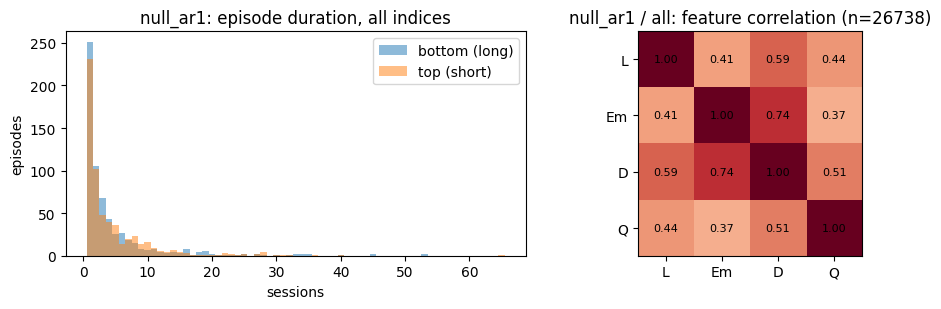

signal=planted: observed episode durations (sessions), in-sample descriptive


episodes                    median                      mean               one_session            
tail bottom (long) top (short) bottom (long) top (short) bottom (long) top (short) bottom (long) top (short)
code                                                                                                        
A1              65          49             2           2         4.538       4.082        0.3846      0.4082
A2              61          80             2           2         4.049       3.425         0.459        0.45
A3              55          82             2           3           3.4       5.427        0.3818      0.2805
E1              55          56             2         3.5         4.345       7.018        0.3818      0.3214
E2              85          76             2           2         4.953       4.408        0.3765      0.3421
E3              45          61             2           2         4.756       3.852        0.4222      0.4918
N1              72          88           2.5           2         4.806        4.92        0.2639      0.3977
N2              54          93             2           2         4.519       4.516        0.3148      0.3656
N3              78          60             2           2         4.103           5         0.359         0.4

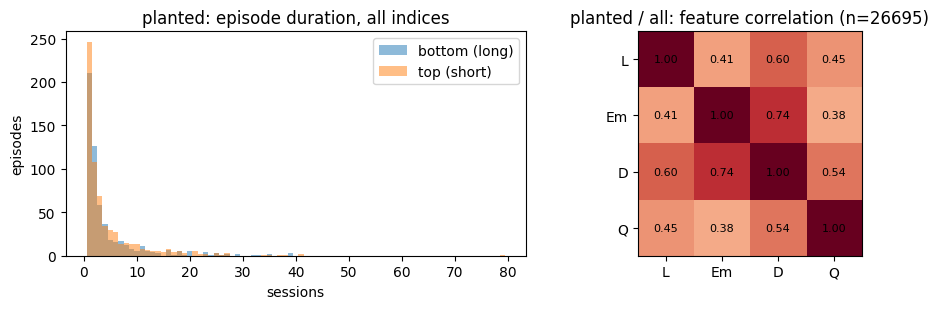

In [11]:
def episodes(panel):
    rows = []
    for code, g in panel.groupby("code"):
        d, E = g.d.to_numpy(), g.E.to_numpy()
        for s in np.flatnonzero(np.nan_to_num(E) != 0):
            t = s
            while t + 1 < len(d) and d[t + 1] == d[s]:
                t += 1
            if t + 1 < len(d) and np.isfinite(d[t + 1]):
                rows.append(dict(code=code, tail="bottom (long)" if d[s] > 0 else "top (short)", length=t - s + 1))
    return pd.DataFrame(rows)


for s, panel in results["panels"].items():
    ep = episodes(panel)
    summary = ep.groupby(["code", "tail"]).length.agg(episodes="size", median="median", mean="mean",
                                                       one_session=lambda x: (x == 1).mean()).unstack("tail")
    print(f"signal={s}: observed episode durations (sessions), in-sample descriptive")
    display(summary)
    fig, axes = plt.subplots(1, 1 + len(results["pools"]), figsize=(5 * (1 + len(results["pools"])), 3.2))
    for tail, g in ep.groupby("tail"):
        axes[0].hist(g.length, bins=np.arange(1, ep.length.max() + 2) - 0.5, alpha=0.5, label=tail)
    axes[0].set(title=f"{s}: episode duration, all indices", xlabel="sessions", ylabel="episodes")
    axes[0].legend()
    for ax, (pool, codes) in zip(axes[1:], results["pools"].items()):
        sub = panel[panel.code.isin(codes) & panel[FEATURES].notna().all(1)]
        cm = sub[["L", "Em", "D", "Q"]].corr()
        ax.imshow(cm, vmin=-1, vmax=1, cmap="RdBu_r")
        ax.set(xticks=range(4), yticks=range(4), xticklabels=cm.columns, yticklabels=cm.index,
               title=f"{s} / {pool}: feature correlation (n={len(sub)})")
        for i in range(4):
            for j in range(4):
                ax.text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
    plt.tight_layout()
    plt.show()

## Mechanism diagnostics

In-sample descriptive views of the observational labels `y_obs`, in volatility
units. "Adjusted" subtracts each index's own mean label (drift control).
Deciles are equal-width bins of `u`, i.e. deciles of the expanding percentile.
The entry-aligned view is the mean signed return `d_s·r_(s+j)/σ_s` after
observed entries: "all entries" includes episodes that have already exited,
"surviving" conditions on the future and is descriptive only.

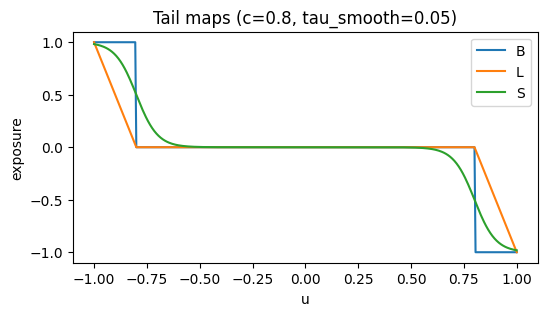

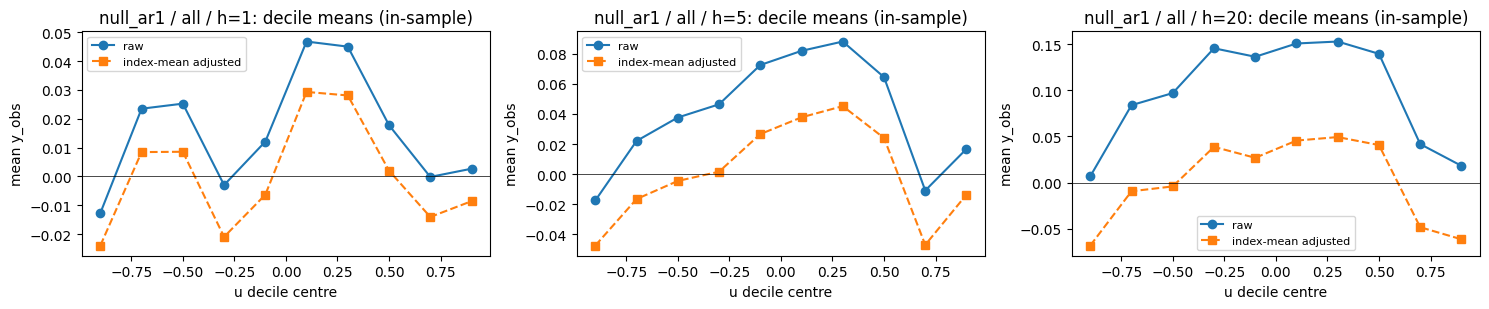

1                      5                      20                
                   n     raw adjusted     n     raw adjusted     n    raw adjusted
u                                                                                 
(-1.001, -0.8]  2832 -0.0127  -0.0239  2812 -0.0175  -0.0474  2765 0.0069  -0.0681
(-0.8, -0.6]    2648  0.0235   0.0084  2638   0.022  -0.0165  2574 0.0839  -0.0093
(-0.6, -0.4]    2680  0.0252   0.0086  2662  0.0376  -0.0045  2606  0.097  -0.0041
(-0.4, -0.2]    2533  -0.003  -0.0209  2509  0.0464   0.0016  2451 0.1455   0.0388
(-0.2, 0.0]     2613  0.0121  -0.0063  2593  0.0725   0.0266  2548 0.1363   0.0269
(0.0, 0.2]      2529  0.0467   0.0293  2519  0.0819   0.0377  2459 0.1507   0.0456
(0.2, 0.4]      2593   0.045   0.0281  2584  0.0881   0.0452  2528 0.1528   0.0494
(0.4, 0.6]      2636  0.0178    0.002  2627  0.0644    0.024  2559 0.1395   0.0407
(0.6, 0.8]      2623 -0.0002   -0.014  2608 -0.0109   -0.047  2538 0.0418  -0.0482
(0.8, 1.0]      2698  0.0027  -0.0086  2673  0.0168  -0.0136  2597 0.0182  -0.0614

null_ar1 / all: within-tail bins, h=1 (in-sample)


,n,raw,adjusted
u,,,
"(-1.001, -0.95]",813,0.0213,0.0124
"(-0.95, -0.9]",642,-0.0118,-0.0238
"(-0.9, -0.85]",693,-0.0873,-0.0991
"(-0.85, -0.8]",684,0.0217,0.0089
"(-0.8, 0.8]",20855,0.0209,0.0044
"(0.8, 0.85]",629,0.0055,-0.0058
"(0.85, 0.9]",636,-0.0168,-0.0289
"(0.9, 0.95]",604,0.0402,0.0274
"(0.95, 1.0]",829,-0.0118,-0.0213


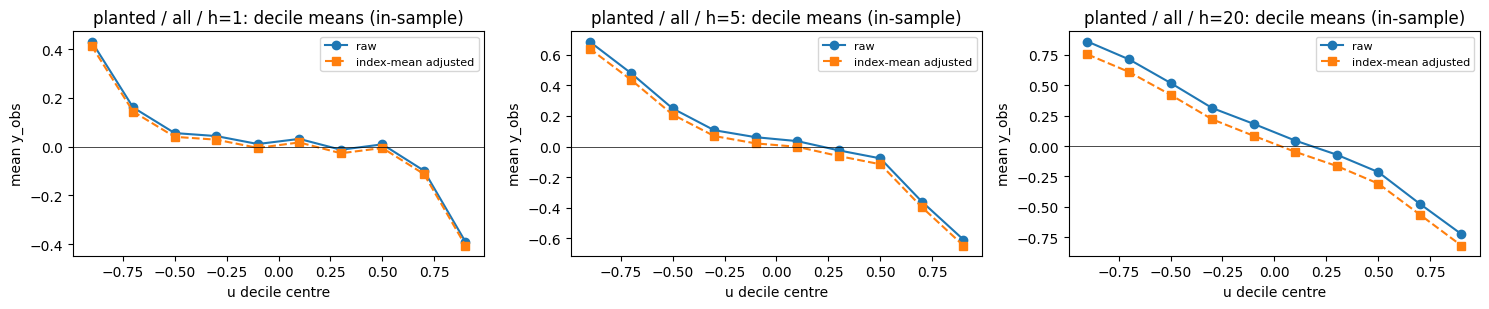

1                      5                      20                 
                   n     raw adjusted     n     raw adjusted     n     raw adjusted
u                                                                                  
(-1.001, -0.8]  2514  0.4316   0.4135  2496  0.6858   0.6401  2447  0.8591   0.7533
(-0.8, -0.6]    2462  0.1608   0.1439  2454   0.479   0.4359  2421  0.7127   0.6091
(-0.6, -0.4]    2564  0.0558   0.0403  2556   0.249   0.2091  2504  0.5187   0.4213
(-0.4, -0.2]    2680  0.0436   0.0288  2668  0.1069    0.069  2597  0.3128   0.2202
(-0.2, 0.0]     2701  0.0109  -0.0051  2677  0.0613   0.0207  2591  0.1825   0.0841
(0.0, 0.2]      2582  0.0319   0.0174  2565  0.0357  -0.0014  2491   0.045  -0.0476
(0.2, 0.4]      2552 -0.0126  -0.0271  2539 -0.0249   -0.062  2487 -0.0711   -0.164
(0.4, 0.6]      2650  0.0095  -0.0054  2631 -0.0769  -0.1153  2580  -0.214  -0.3088
(0.6, 0.8]      2668 -0.0985  -0.1124  2657 -0.3593  -0.3955  2613 -0.4749  -0.5634
(0.8, 1.0]      3012 -0.3906  -0.4058  2982 -0.6074   -0.646  2894 -0.7238  -0.8181

planted / all: within-tail bins, h=1 (in-sample)


,n,raw,adjusted
u,,,
"(-1.001, -0.95]",767,0.3784,0.3598
"(-0.95, -0.9]",618,0.4284,0.4104
"(-0.9, -0.85]",557,0.5425,0.5236
"(-0.85, -0.8]",572,0.3985,0.3815
"(-0.8, 0.8]",20859,0.0239,0.0088
"(0.8, 0.85]",645,-0.327,-0.3425
"(0.85, 0.9]",695,-0.3823,-0.3977
"(0.9, 0.95]",773,-0.4404,-0.4547
"(0.95, 1.0]",899,-0.3999,-0.4156


In [12]:
st = SETTINGS
grid = np.linspace(-1, 1, 401)
mp = state_from_u(grid, st)
fig, ax = plt.subplots(figsize=(6, 3))
for k in ("B", "L", "S"):
    ax.plot(grid, mp[k], label=k)
ax.set(title=f"Tail maps (c={st['c']}, tau_smooth={st['tau_smooth']})", xlabel="u", ylabel="exposure")
ax.legend()
plt.show()

dec_edges = np.linspace(-1, 1, 11)
tail_edges = np.r_[-np.linspace(1, st["c"], 5), np.linspace(st["c"], 1, 5)]


def binned(sub, col, edges):
    adj = sub[col] - sub.groupby("code")[col].transform("mean")
    b = pd.cut(sub.u, edges, include_lowest=True)
    return pd.DataFrame(dict(n=sub.groupby(b, observed=False)[col].count(), raw=sub.groupby(b, observed=False)[col].mean(),
                             adjusted=adj.groupby(b, observed=False).mean()))


for s, panel in results["panels"].items():
    for pool, codes in results["pools"].items():
        sub = panel[panel.code.isin(codes)]
        fig, axes = plt.subplots(1, len(st["horizons"]), figsize=(5 * len(st["horizons"]), 3.2))
        dec_tables = {}
        for ax, h in zip(axes, st["horizons"]):
            t = binned(sub[sub[f"y_obs_{h}"].notna()], f"y_obs_{h}", dec_edges)
            dec_tables[h] = t
            mid = (dec_edges[:-1] + dec_edges[1:]) / 2
            ax.plot(mid, t.raw, "o-", label="raw")
            ax.plot(mid, t.adjusted, "s--", label="index-mean adjusted")
            ax.axhline(0, color="k", lw=0.5)
            ax.set(title=f"{s} / {pool} / h={h}: decile means (in-sample)", xlabel="u decile centre", ylabel="mean y_obs")
            ax.legend(fontsize=8)
        plt.tight_layout()
        plt.show()
        display(pd.concat({h: t for h, t in dec_tables.items()}, axis=1).round(4))
        print(f"{s} / {pool}: within-tail bins, h=1 (in-sample)")
        display(binned(sub[sub.y_obs_1.notna()], "y_obs_1", tail_edges).dropna(how="all").round(4))

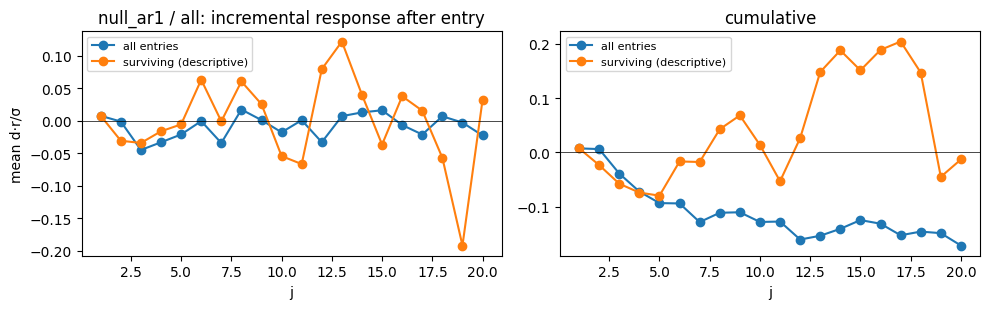

null_ar1 / all: entries counted at j=1: 1175, surviving at j=20: 46
null_ar1 / all: mean d·y_obs_1 by age × depth tertile (in-sample, observed episodes)


mean                   count          
depth         shallow     mid    deep shallow  mid deep
age                                                    
(-0.001, 1.0]  0.0099  -0.056  0.0785    1068  662  172
(1.0, 6.0]    -0.0477 -0.0387  0.0476     476  670  673
(6.0, 64.0]   -0.0157  0.0272 -0.0213     285  498  983

null_ar1 / all: mean d·y_obs_1 by velocity × depth tertile (in-sample, observed episodes)


mean                   count            
depth    shallow     mid    deep shallow   mid  deep
velocity                                            
inward    0.0055  0.0288 -0.0222     670   607   539
outward  -0.0175 -0.0547  0.0283    1159  1223  1289

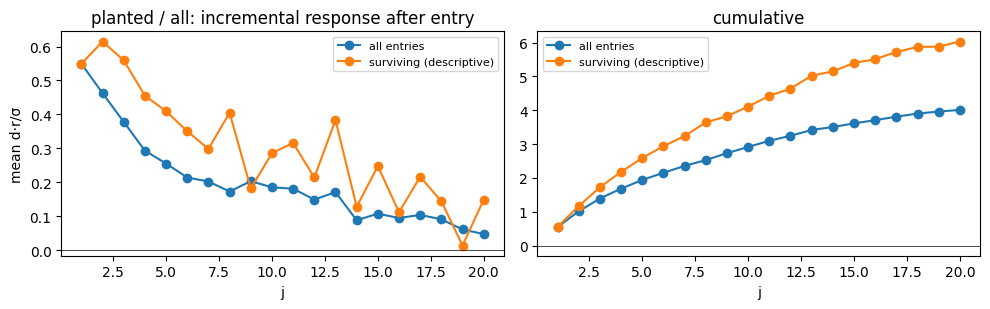

planted / all: entries counted at j=1: 1152, surviving at j=20: 48
planted / all: mean d·y_obs_1 by age × depth tertile (in-sample, observed episodes)


mean                 count          
depth         shallow    mid   deep shallow  mid deep
age                                                  
(-0.001, 1.0]   0.463 0.7051 0.8181    1112  592  182
(1.0, 6.0]     0.3447 0.4469 0.4518     418  656  681
(6.0, 78.0]    0.1142 0.2174 0.2766     289  571  956

planted / all: mean d·y_obs_1 by velocity × depth tertile (in-sample, observed episodes)


mean                 count            
depth    shallow    mid   deep shallow   mid  deep
velocity                                          
inward    0.1849 0.2517 0.2521     664   618   482
outward   0.4928 0.5655 0.4483    1155  1201  1337

In [13]:
def entry_response(panel, J):
    """Mean signed normalized return j sessions after observed entries: all entries and surviving episodes."""
    inc, surv = [], []
    for _, g in panel.groupby("code"):
        d, r, sig, E = g.d.to_numpy(), g.r.to_numpy(), g.sigma.to_numpy(), g.E.to_numpy()
        n = len(d)
        for s in np.flatnonzero((np.nan_to_num(E) != 0) & np.isfinite(sig)):
            if s + J >= n:
                continue
            path = d[s] * r[s + 1:s + J + 1] / sig[s]
            alive = np.cumprod(d[s:s + J] == d[s]).astype(bool)  # in the same episode through close s+j-1
            inc.append(path)
            surv.append(np.where(alive, path, np.nan))
    inc, surv = np.array(inc), np.array(surv)
    return pd.DataFrame(dict(all_mean=np.nanmean(inc, 0), all_n=np.isfinite(inc).sum(0),
                             surviving_mean=np.nanmean(surv, 0), surviving_n=np.isfinite(surv).sum(0)),
                        index=pd.RangeIndex(1, J + 1, name="j"))


J = max(st["horizons"])
for s, panel in results["panels"].items():
    for pool, codes in results["pools"].items():
        sub = panel[panel.code.isin(codes)]
        er = entry_response(sub, J)
        fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
        for col, lab in (("all_mean", "all entries"), ("surviving_mean", "surviving (descriptive)")):
            axes[0].plot(er.index, er[col], "o-", label=lab)
            axes[1].plot(er.index, er[col].fillna(0).cumsum(), "o-", label=lab)
        axes[0].set(title=f"{s} / {pool}: incremental response after entry", xlabel="j", ylabel="mean d·r/σ")
        axes[1].set(title="cumulative", xlabel="j")
        for ax in axes:
            ax.axhline(0, color="k", lw=0.5)
            ax.legend(fontsize=8)
        plt.tight_layout()
        plt.show()
        print(f"{s} / {pool}: entries counted at j=1: {er.all_n.iloc[0]}, surviving at j={J}: {er.surviving_n.iloc[-1]}")
        tail = sub[(sub.d != 0) & sub.A.notna() & sub.y_obs_1.notna()].assign(signed=lambda f: f.d * f.y_obs_1)
        tail["depth"] = pd.qcut(tail.a, 3, labels=["shallow", "mid", "deep"])
        tail["age"] = pd.qcut(tail.A, 3, duplicates="drop")
        tail["velocity"] = np.where(tail.V > 0, "outward", "inward")
        for by in ("age", "velocity"):
            t = tail.pivot_table(index=by, columns="depth", values="signed", aggfunc=["mean", "count"], observed=False)
            print(f"{s} / {pool}: mean d·y_obs_1 by {by} × depth tertile (in-sample, observed episodes)")
            display(t.round(4))

## Walk-forward forecasts

Fixed boundaries shared across each pool; each refit trains on every admitted row
(label window ended before the boundary) since each index's first valid row.
`obs` labels diagnose the mechanism; only `lag` labels feed the weight simulation.
Δ columns are mean squared-loss differences (negative = better than the reference).

In [14]:
oos = pd.concat([oos_metrics(pred, run).assign(signal=k[0], pool=k[1], label=k[2], h=k[3], run=run)
                 for k, pred in results["preds"].items() for run in RUNS]).reset_index()
excluded = pd.DataFrame([dict(signal=s, pool=pool, label=label, h=h, rows=len(p),
                              feature_invalid=int((~p[FEATURES].notna().all(1)).sum()),
                              label_invalid=int((p[FEATURES].notna().all(1) & p[f"y_{label}_{h}"].isna()).sum()))
                         for (s, pool, label, h) in results["preds"]
                         for p in [results["panels"][s][results["panels"][s].code.isin(results["pools"][pool])]]])
print("Rows excluded from the common valid set (all periods)")
display(excluded)
for metric in ("R2", "d_vs_M0", "d_vs_B"):
    print(f"Out-of-sample {metric} (rows: signal/pool/label/model; columns: h/run)")
    display(oos.pivot_table(index=["signal", "pool", "label", "model"], columns=["h", "run"], values=metric, sort=False))

Rows excluded from the common valid set (all periods)


,signal,pool,label,h,rows,feature_invalid,label_invalid
0,null_ar1,all,obs,1,27000,262,514
1,null_ar1,all,obs,5,27000,262,674
2,null_ar1,all,obs,20,27000,262,1267
3,null_ar1,all,lag,1,27000,262,554
4,null_ar1,all,lag,5,27000,262,714
5,null_ar1,all,lag,20,27000,262,1305
6,planted,all,obs,1,27000,305,504
7,planted,all,obs,5,27000,305,663
8,planted,all,obs,20,27000,305,1247
9,planted,all,lag,1,27000,305,544


Out-of-sample R2 (rows: signal/pool/label/model; columns: h/run)


h                                 1                     5                   20           
run                            index       none      index      none     index       none
signal   pool label model                                                                
null_ar1 all  obs   B     -0.0002357   0.000172 -0.0009951 0.0003133 -0.004074  -0.001836
                    S     -0.0002261  0.0001837  -0.001125 0.0001714 -0.004803  -0.002575
                    s(u)  -0.0004512 -0.0003805  -0.001493 -0.002738 -0.006812  -0.008269
                    M0    -0.0002987   0.000133     -0.001 0.0003621  -0.00333 -0.0009684
                    M1     -0.000262  0.0001801 -0.0009251 0.0005241  -0.00458  -0.001566
                    M2    -0.0003535  8.024e-05  -0.001118 0.0003077  -0.00427  -0.001484
                    M3    -0.0003277  0.0001119  -0.001117 0.0002451 -0.003331 -0.0009021
                    M4    -0.0003106  0.0001297   -0.00103 0.0003892 -0.005002  -0.001965
                    G     -0.0005193 -0.0004096  -0.001597 -0.002936 -0.007348  -0.008298
                    zero   0.0004188  0.0004188   0.001317  0.001317  0.002158   0.002158
                    mean           0          0          0         0         0          0
              lag   B     -0.0002533  6.653e-05  -0.001073 0.0001813 -0.004165  -0.002103
                    S     -0.0002392  7.478e-05  -0.001235 5.973e-06 -0.004964  -0.002908
                    s(u)  -0.0003323 -0.0003293  -0.001587 -0.002369 -0.006591  -0.008527
                    M0    -0.0001486  0.0001802  -0.001001 0.0002986 -0.003278  -0.001101
                    M1     -0.000138  0.0002104  -0.001042 0.0003595 -0.004659  -0.001812
                    M2    -0.0002926  6.087e-05  -0.001144  0.000224 -0.004215  -0.001593
                    M3    -0.0001455  0.0001901  -0.001153 0.0001331 -0.003255  -0.001004
                    M4    -0.0003085  3.739e-05  -0.001187 0.0001809 -0.005107  -0.002218
                    G     -0.0004598 -0.0004495  -0.001754 -0.002639 -0.007451  -0.008548
                    zero   0.0003206  0.0003206   0.001258  0.001258  0.001969   0.001969
                    mean           0          0          0         0         0          0
planted  all  obs   B        0.03744      0.037    0.07982   0.07842   0.09186    0.08698
                    S        0.03998     0.0394    0.09495   0.09291    0.1146     0.1081
                    s(u)     0.03896    0.03853     0.1091    0.1067    0.1566     0.1485
                    M0       0.02829    0.02804    0.05895   0.05825   0.07147    0.06832
                    M1       0.04177    0.04146    0.09162   0.09082    0.1002    0.09636
                    M2       0.04436    0.04406    0.08909   0.08825   0.09167    0.08804
                    M3       0.03405    0.03393    0.06448   0.06411   0.07327    0.07056
                    M4       0.04657    0.04631    0.09629   0.09547    0.1018    0.09774
                    G         0.0468    0.04637     0.1168    0.1152    0.1575     0.1521
                    zero   0.0004648  0.0004648   0.001674  0.001674  0.002425   0.002425
                    mean           0          0          0         0         0          0
              lag   B        0.02287    0.02255    0.05566   0.05459   0.07598    0.07146
                    S        0.02743    0.02694    0.07014   0.06845   0.09621    0.09013
                    s(u)     0.02926     0.0286    0.09208    0.0912    0.1391     0.1316
                    M0       0.01765    0.01748    0.04162   0.04118   0.05946    0.05658
                    M1       0.02676    0.02654    0.06598   0.06546   0.08205    0.07844
                    M2       0.02661    0.02636    0.06001   0.05944   0.07422    0.07086
                    M3       0.01977    0.01967    0.04395   0.04375   0.06031    0.05776
                    M4       0.02827    0.02804    0.06742   0.06683   0.08317    0.07935
                    G        0.03192    

Out-of-sample d_vs_M0 (rows: signal/pool/label/model; columns: h/run)


h                                 1                     5                     20           
run                            index       none      index       none      index       none
signal   pool label model                                                                  
null_ar1 all  obs   B     -6.511e-05 -4.038e-05 -5.818e-06  5.806e-05   0.001131   0.001319
                    S     -7.499e-05 -5.238e-05  0.0001482  0.0002268   0.002241   0.002444
                    s(u)   0.0001574  0.0005303  0.0005862   0.003688   0.005297    0.01111
                    M0             0          0          0          0          0          0
                    M1    -3.798e-05 -4.865e-05 -8.909e-05 -0.0001927   0.001902  0.0009097
                    M2     5.652e-05  5.444e-05  0.0001409  6.469e-05    0.00143  0.0007846
                    M3     2.992e-05  2.177e-05  0.0001395  0.0001392  9.202e-07 -0.0001008
                    M4     1.224e-05  3.393e-06  3.589e-05 -3.223e-05   0.002543   0.001515
                    G      0.0002278  0.0005603  0.0007097   0.003923   0.006112    0.01115
                    zero   -0.000741 -0.0002952  -0.002757  -0.001136  -0.008348  -0.004756
                    mean  -0.0003085  0.0001373   -0.00119  0.0004308  -0.005066  -0.001473
              lag   B      0.0001082  0.0001176  8.607e-05  0.0001396   0.001349   0.001525
                    S      9.368e-05  0.0001091  0.0002784  0.0003484   0.002565    0.00275
                    s(u)   0.0001899   0.000527  0.0006979   0.003175    0.00504     0.0113
                    M0             0          0          0          0          0          0
                    M1    -1.103e-05 -3.116e-05  4.907e-05 -7.248e-05   0.002101   0.001082
                    M2     0.0001489  0.0001235  0.0001697  8.888e-05   0.001425  0.0007487
                    M3    -3.219e-06 -1.019e-05  0.0001804   0.000197 -3.532e-05 -0.0001472
                    M4     0.0001653  0.0001477  0.0002214  0.0001402   0.002782     0.0017
                    G      0.0003219  0.0006514  0.0008956   0.003497   0.006348    0.01133
                    zero  -0.0004854 -0.0001452   -0.00269  -0.001142  -0.007983   -0.00467
                    mean  -0.0001538  0.0001864  -0.001192  0.0003555  -0.004987  -0.001674
planted  all  obs   B      -0.009447  -0.009257    -0.0248   -0.02397   -0.03096   -0.02833
                    S       -0.01208   -0.01174   -0.04279   -0.04119   -0.06544   -0.06033
                    s(u)    -0.01102   -0.01083   -0.05956   -0.05756    -0.1293    -0.1218
                    M0             0          0          0          0          0          0
                    M1      -0.01392   -0.01387   -0.03883    -0.0387   -0.04368   -0.04256
                    M2      -0.01661   -0.01655   -0.03582   -0.03565   -0.03067   -0.02993
                    M3     -0.005948  -0.006082  -0.006578   -0.00697  -0.002744  -0.003392
                    M4      -0.01889   -0.01888   -0.04437   -0.04423   -0.04603   -0.04466
                    G       -0.01912   -0.01894   -0.06869    -0.0677    -0.1306    -0.1273
                    zero     0.02876    0.02849    0.06805    0.06722     0.1048     0.1001
                    mean     0.02924    0.02897    0.07004    0.06921     0.1085     0.1037
              lag   B      -0.005401  -0.005245   -0.01668   -0.01594   -0.02509   -0.02259
                    S       -0.01011  -0.009786    -0.0339   -0.03241   -0.05582   -0.05095
                    s(u)    -0.01201   -0.01151   -0.05998   -0.05946    -0.1209    -0.1139
                    M0             0          0          0          0          0          0
                    M1     -0.009424  -0.009375   -0.02895   -0.02886   -0.03431    -0.0332
                    M2     -0.009269  -0.009191   -0.02186   -0.02171   -0.02241   -0.02169
                    M3     -0.002185  -0.002266  -0.002766  -0.003053  -0.001291   -0.00179
                    M4      -0.01099   -0.01

Out-of-sample d_vs_B (rows: signal/pool/label/model; columns: h/run)


h                                 1                     5                    20           
run                            index       none      index       none     index       none
signal   pool label model                                                                 
null_ar1 all  obs   B              0          0          0          0         0          0
                    S     -9.878e-06   -1.2e-05   0.000154  0.0001688   0.00111   0.001125
                    s(u)   0.0002225  0.0005707  0.0005921    0.00363  0.004166   0.009787
                    M0     6.511e-05  4.038e-05  5.818e-06 -5.806e-05 -0.001131  -0.001319
                    M1     2.713e-05 -8.275e-06 -8.327e-05 -0.0002508 0.0007705 -0.0004097
                    M2     0.0001216  9.482e-05  0.0001467  6.636e-06 0.0002992 -0.0005348
                    M3     9.503e-05  6.215e-05  0.0001454  8.115e-05  -0.00113   -0.00142
                    M4     7.735e-05  4.377e-05  4.171e-05 -9.028e-05  0.001412   0.000196
                    G      0.0002929  0.0006006  0.0007156   0.003865  0.004981    0.00983
                    zero  -0.0006759 -0.0002548  -0.002751  -0.001194 -0.009479  -0.006075
                    mean  -0.0002434  0.0001777  -0.001184  0.0003727 -0.006197  -0.002793
              lag   B              0          0          0          0         0          0
                    S     -1.453e-05 -8.532e-06  0.0001924  0.0002088  0.001215   0.001225
                    s(u)   8.173e-05  0.0004094  0.0006118   0.003035  0.003691   0.009772
                    M0    -0.0001082 -0.0001176 -8.607e-05 -0.0001396 -0.001349  -0.001525
                    M1    -0.0001192 -0.0001488 -3.699e-05 -0.0002121 0.0007518 -0.0004428
                    M2     4.067e-05  5.854e-06  8.364e-05 -5.075e-05 7.625e-05 -0.0007764
                    M3    -0.0001114 -0.0001278  9.436e-05  5.741e-05 -0.001384  -0.001672
                    M4      5.71e-05  3.014e-05  0.0001353  5.781e-07  0.001433  0.0001751
                    G      0.0002136  0.0005338  0.0008095   0.003357  0.004998   0.009804
                    zero  -0.0005936 -0.0002628  -0.002776  -0.001282 -0.009332  -0.006195
                    mean   -0.000262  6.881e-05  -0.001278  0.0002159 -0.006336  -0.003199
planted  all  obs   B              0          0          0          0         0          0
                    S      -0.002629  -0.002479   -0.01799   -0.01722  -0.03448     -0.032
                    s(u)   -0.001572  -0.001578   -0.03477   -0.03359  -0.09831   -0.09347
                    M0      0.009447   0.009257     0.0248    0.02397   0.03096    0.02833
                    M1     -0.004476   -0.00461   -0.01403   -0.01473  -0.01272   -0.01424
                    M2     -0.007158  -0.007293   -0.01102   -0.01168 0.0002864  -0.001604
                    M3      0.003499   0.003175    0.01822      0.017   0.02821    0.02493
                    M4     -0.009442  -0.009624   -0.01957   -0.02026  -0.01507   -0.01634
                    G      -0.009675  -0.009686   -0.04389   -0.04373  -0.09966   -0.09894
                    zero      0.0382    0.03775    0.09285    0.09119    0.1358     0.1284
                    mean     0.03868    0.03823    0.09484    0.09318    0.1395     0.1321
              lag   B              0          0          0          0         0          0
                    S       -0.00471  -0.004541   -0.01722   -0.01648  -0.03073   -0.02836
                    s(u)   -0.006611  -0.006267    -0.0433   -0.04352  -0.09586   -0.09132
                    M0      0.005401   0.005245    0.01668    0.01594   0.02509    0.02259
                    M1     -0.004023   -0.00413   -0.01227   -0.01292 -0.009221   -0.01061
                    M2     -0.003868  -0.003946  -0.005178  -0.005775  0.002674  0.0009042
                    M3      0.003216   0.002979    0.01392    0.01288    0.0238     0.0208
                    M4     -0.005585  -0.005682   -0.01399   -0.01455  -0.01092   -0.01

In [15]:
coef_rows = []
for key, log in results["logs"].items():
    for _, r in log[log.ns == 0].iterrows():
        for f, b in zip(MODELS[r.model], r.beta):
            coef_rows.append(dict(signal=key[0], pool=key[1], label=key[2], h=key[3], run=r.run, model=r.model,
                                  feature=f, fold=r.fold, beta=b, rank=r["rank"], ncol=r.ncol))
coefs = pd.DataFrame(coef_rows)
last = coefs[coefs.fold == coefs.fold.max()]
print("Last-fold coefficients (volatility units per unit feature)")
display(last.pivot_table(index=["signal", "pool", "label", "model", "feature"], columns=["h", "run"], values="beta", sort=False))
deficient = coefs[coefs["rank"] < coefs.ncol]
print(f"rank-deficient fits: {deficient[['signal', 'pool', 'label', 'h', 'run', 'model', 'fold']].drop_duplicates().shape[0]}")
spread = coefs.groupby(["signal", "pool", "label", "h", "run", "model", "feature"]).beta.agg(["min", "mean", "max"])
print("Coefficient range across folds, M4")
display(spread.xs("M4", level="model").unstack("run").round(3))

Last-fold coefficients (volatility units per unit feature)

h                                        1                    5                   20         
run                                   index      none      index       none    index     none
signal   pool label model feature                                                            
null_ar1 all  obs   B     B       -0.001499   -0.0016  -0.003141  -0.003288  0.02387  0.02322
                    S     S       -0.001158 -0.001448   0.005438     0.0048  0.03675  0.03486
                    M0    L        0.008784  0.008085    0.01143    0.00992  0.04768  0.04416
                    M1    L          0.0212   0.02231    0.03689    0.03927  0.06385  0.06933
                          Em         -0.082   -0.0931    -0.1688     -0.193  -0.1085  -0.1673
                    M2    L         0.01247   0.01418    0.02515    0.02922  0.06252  0.07257
                          D       -0.006097  -0.01006    -0.0228   -0.03199 -0.02487 -0.04747
                    M3    L         0.01371   0.01442    0.01305     0.0148  0.08311  0.08697
                          Q         -0.0586  -0.07527   -0.01935   -0.05816   -0.424  -0.5118
                    M4    L         0.01262   0.01462     0.0201    0.02487  0.07765  0.08886
                          Em        -0.1332   -0.1416    -0.2424    -0.2591  -0.1238  -0.1627
                          D         0.03452   0.03364    0.04095     0.0381  0.04281  0.03445
                          Q        -0.05375  -0.06292     0.0388    0.01739  -0.4436  -0.4881
              lag   B     B       -0.006014 -0.006035 -0.0007375 -0.0009092  0.02558  0.02505
                    S     S       -0.001073 -0.001318    0.00821   0.007515  0.03928  0.03753
                    M0    L       -0.008002 -0.008562   0.008541   0.006987  0.04725  0.04396
                    M1    L         0.00192  0.003116    0.02944    0.03177  0.06006  0.06574
                          Em       -0.06556  -0.07653    -0.1386     -0.163 -0.08599  -0.1448
                    M2    L       -0.006287 -0.004481    0.01893      0.023  0.06282  0.07314
                          D        -0.00284 -0.006738   -0.01727   -0.02655 -0.02611 -0.04877
                    M3    L        0.004152  0.004971   0.009433    0.01116  0.08552   0.0897
                          Q         -0.1447    -0.161   -0.01065   -0.04975  -0.4576  -0.5464
                    M4    L       -0.001486 0.0005822    0.01462    0.01938  0.08009  0.09159
                          Em        -0.1128   -0.1211    -0.2036    -0.2204 -0.07803  -0.1168
                          D          0.0406   0.03975    0.03616    0.03325  0.03185  0.02342
                          Q         -0.1663   -0.1752    0.03418    0.01258  -0.4809  -0.5265
planted  all  obs   B     B          0.4109    0.4065     0.6462     0.6388   0.8027    0.794
                    S     S          0.4854    0.4793     0.8009     0.7907    1.011   0.9996
                    M0    L          0.5883    0.5814      0.915     0.9032    1.142    1.127
                    M1    L          0.4213    0.4131     0.6331     0.6184    0.824   0.8028
                          Em          1.153     1.156      1.949       1.96    2.188    2.219
                    M2    L          0.2886    0.2806     0.4692     0.4547   0.7005   0.6791
                          D          0.5037    0.5051     0.7496     0.7538   0.7375   0.7474
                    M3    L          0.4611    0.4529     0.7814     0.7665    1.047    1.025
                          Q            1.44     1.459      1.513      1.554     1.07    1.143
                    M4    L            0.28    0.2712     0.4918     0.4755   0.7496   0.7257
                          Em         0.5632    0.5651      1.266      1.275    1.744    1.773
                          D          0.3064    0.3055      0.405     0.4028   0.3058   0.3014
                          Q          0.5035    0.5231   -0.00903    0.03032  -0.4944  -0.4297
              lag   B     B          0.3281    0.324

rank-deficient fits: 0
Coefficient range across folds, M4


min          mean           max       
run                             index   none  index   none  index   none
signal   pool label h  feature                                          
null_ar1 all  lag   1  D       -0.011 -0.012  0.034  0.033   0.09   0.09
                       Em      -0.147 -0.163   -0.1 -0.105 -0.047 -0.045
                       L       -0.001  0.001  0.022  0.024  0.046  0.048
                       Q       -0.252 -0.256 -0.197 -0.207 -0.128  -0.14
                    5  D        0.001 -0.001  0.019  0.017  0.046  0.044
                       Em      -0.204  -0.22 -0.123 -0.133 -0.028 -0.065
                       L        0.015  0.019  0.084  0.088  0.139  0.142
                       Q       -0.293 -0.318  -0.15 -0.171  0.034  0.013
                    20 D        0.025  0.014  0.055  0.048  0.112  0.101
                       Em      -0.078 -0.117  0.078  0.051  0.484  0.404
                       L         0.08  0.092   0.17  0.176  0.249  0.252
                       Q        -0.78 -0.805 -0.646 -0.687 -0.481 -0.526
              obs   1  D        0.035  0.034  0.046  0.046  0.055  0.055
                       Em       -0.18 -0.183 -0.142 -0.148 -0.119 -0.117
                       L        0.013  0.014  0.028   0.03  0.046  0.052
                       Q       -0.056 -0.063 -0.018 -0.029  0.054  0.041
                    5  D        0.006  0.002  0.029  0.027  0.067  0.065
                       Em      -0.242 -0.259 -0.186 -0.197  -0.11 -0.117
                       L         0.02  0.025  0.078  0.082  0.121  0.124
                       Q       -0.159  -0.18 -0.059 -0.081   0.07  0.045
                    20 D        0.042  0.032  0.066   0.06  0.123  0.112
                       Em      -0.124 -0.163  0.018 -0.009  0.411  0.333
                       L        0.078  0.089  0.168  0.173  0.252  0.255
                       Q       -0.741 -0.766 -0.601 -0.641 -0.444 -0.488
planted  all  lag   1  D         0.18   0.18  0.228  0.228  0.249  0.248
                       Em       0.378   0.38  0.495  0.493  0.569  0.568
                       L          0.2  0.192  0.223  0.216  0.231  0.222
                       Q        0.098   0.11  0.144  0.156  0.227  0.232
                    5  D        0.223  0.222  0.251  0.252  0.267   0.27
                       Em       1.012  1.024  1.257  1.256  1.374  1.382
                       L        0.409  0.411   0.45  0.436  0.467  0.449
                       Q       -0.471 -0.447 -0.391 -0.368 -0.313 -0.275
                    20 D        0.197  0.211   0.22  0.226  0.254   0.25
                       Em       1.612   1.65  1.693  1.698   1.75  1.766
                       L        0.586  0.579  0.675  0.653  0.749  0.716
                       Q       -0.614  -0.56 -0.508 -0.481 -0.385 -0.388
              obs   1  D        0.227  0.228  0.276  0.276  0.306  0.305
                       Em       0.427   0.42  0.501  0.497   0.57  0.567
                       L         0.28  0.271  0.291  0.282  0.306  0.296
                       Q        0.229  0.244  0.377  0.391  0.504  0.523
                    5  D        0.339  0.337  0.373  0.374  0.405  0.403
                       Em       0.957  0.966  1.184   1.18  1.315  1.316
                       L        0.459  0.458  0.492  0.477  0.508  0.485
                       Q       -0.156  -0.13 -0.095  -0.07 -0.009   0.03
                    20 D        0.233  0.248  0.265  0.271  0.306  0.301
                       Em       1.686  1.724  1.781  1.786  1.853  1.869
                       L        0.632  0.629  0.721  0.698  0.795  0.762
                       Q       -0.503 -0.463 -0.417 -0.387 -0.317 -0.325

Selected spline penalty per fit (80/20 split by date inside each training window)


fold                                   0     1     2     3     4     5     6     7
signal   pool label h  run   model                                                
null_ar1 all  obs   1  index s(u)  1e+05 1e+07 1e+07   0.1   0.1 1e+07  1000 1e+07
                             G     1e+05 1e+07 1e+07   0.1   0.1 1e+07  1000 1e+07
                       none  s(u)  1e+07  1000 1e+07    10   0.1  1000 1e+07 1e+07
                             G     1e+07  1000 1e+07   0.1   0.1  1000 1e+07 1e+07
                    5  index s(u)  1e+05 1e+07 1e+07 1e+07  1000 1e+07  1000 1e+07
                             G     1e+05 1e+07 1e+07 1e+07  1000 1e+07  1000 1e+07
                       none  s(u)  1e+07  1000 1e+07 1e+05    10    10 1e+07 1e+07
                             G     1e+07  1000 1e+07 1e+05    10    10 1e+07 1e+07
                    20 index s(u)  1e+07 1e+07 1e+07 1e+07 1e+07 1e+07 1e+05 1e+07
                             G     1e+07 1e+07 1e+07 1e+07 1e+07 1e+07 1e+05 1e+07
                       none  s(u)   1000  1000 1e+07  1000   0.1  1000 1e+07 1e+07
                             G      1000  1000 1e+07  1000   0.1  1000 1e+07 1e+07
              lag   1  index s(u)   1000 1e+07 1e+07 1e+07 1e+05 1e+07  1000  1000
                             G      1000 1e+07 1e+07 1e+07 1e+07 1e+07  1000  1000
                       none  s(u)  1e+07  1000 1e+07 1e+05  1000 1e+05 1e+07 1e+07
                             G     1e+07  1000 1e+07 1e+05  1000 1e+05 1e+07 1e+07
                    5  index s(u)  1e+05 1e+07 1e+07 1e+07    10 1e+07  1000 1e+07
                             G     1e+05 1e+07 1e+07 1e+07    10 1e+07  1000 1e+07
                       none  s(u)     10  1000 1e+07 1e+05    10    10 1e+07 1e+07
                             G      1000  1000 1e+07 1e+05    10    10 1e+07 1e+07
                    20 index s(u)  1e+07 1e+07 1e+07 1e+07 1e+07 1e+07  1000 1e+07
                             G     1e+07 1e+07 1e+07 1e+07 1e+07 1e+07 1e+05 1e+07
                       none  s(u)   1000  1000 1e+07  1000   0.1  1000 1e+07 1e+07
                             G      1000  1000 1e+07  1000   0.1  1000 1e+07 1e+07
planted  all  obs   1  index s(u)     10  1000   0.1   0.1   0.1   0.1    10    10
                             G        10 1e+07 1e+07  1000    10    10    10  1000
                       none  s(u)    0.1  1000   0.1   0.1   0.1   0.1   0.1   0.1
                             G        10 1e+05  1000  1000   0.1    10    10    10
                    5  index s(u)  1e+07  1000 1e+07   0.1    10    10   0.1   0.1
                             G     1e+07  1000   0.1   0.1    10    10  1000    10
                       none  s(u)     10  1000  1000   0.1   0.1    10    10   0.1
                             G        10  1000   0.1   0.1    10    10 1e+07    10
                    20 index s(u)  1e+07    10 1e+07 1e+05 1e+07 1e+07 1e+05    10
                             G     1e+07    10    10 1e+05 1e+07 1e+07  1000    10
                       none  s(u)     10    10  1000   0.1   0.1 1e+05 1e+07    10
                             G        10    10  1000   0.1  1000 1e+05 1e+07    10
              lag   1  index s(u)     10 1e+05    10   0.1    10    10    10   0.1
                             G        10 1e+05   0.1   0.1    10    10  1000   0.1
                       none  s(u)     10 1e+05    10   0.1    10   0.1   0.1   0.1
                             G        10 1e+05   0.1   0.1    10 1e+07 1e+07   0.1
                    5  index s(u)  1e+07  1000 1e+07   0.1    10    10    10    10
                             G     1e+07  1000   0.1   0.1  1000 1e+07  1000    10
                       none  s(u)   1000  1000   0.1   0.1   0.1    10 1e+07    10
                             G        10  1000   0.1   0.1    10  1000 1e+07    10
                    20 index s(u)   1000    10    10 1e+05 1e+07 1e+07 1e+05    10
                             G       0.1    10   0.1 1e+05 1e+07 1e+07  1000    10
                

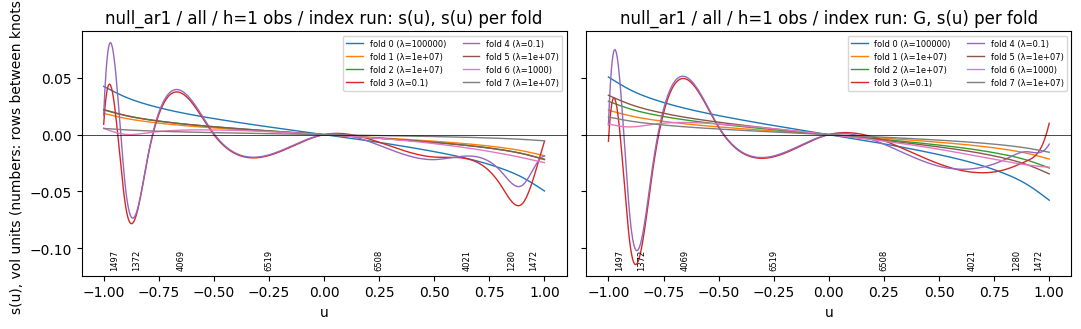

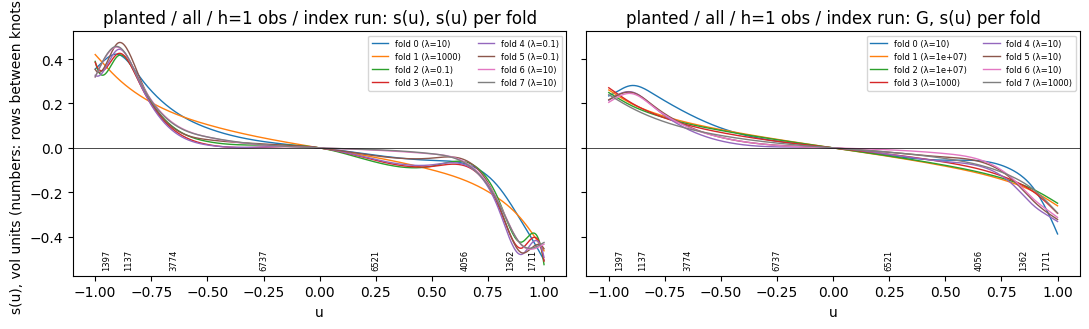

In [16]:
lam_tab = pd.concat([log[log.ns > 0][["fold", "run", "model", "lam", "split", "n_fit", "n_val"]].assign(
    signal=k[0], pool=k[1], label=k[2], h=k[3]) for k, log in results["logs"].items()])
print("Selected spline penalty per fit (80/20 split by date inside each training window)")
display(lam_tab.pivot_table(index=["signal", "pool", "label", "h", "run", "model"], columns="fold", values="lam", sort=False))

for s in results["panels"]:
    for pool, codes in results["pools"].items():
        panel = results["panels"][s]
        sub = panel[panel.code.isin(codes) & panel[FEATURES].notna().all(1)]
        fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
        log = results["logs"][(s, pool, "obs", 1)]
        Bg = spline_basis(grid, st)
        for ax, model in zip(axes, (SPLINE, "G")):
            for _, r in log[(log.model == model) & (log.run == "index")].iterrows():
                ax.plot(grid, Bg @ r.beta[:r.ns], lw=1, label=f"fold {r.fold} (λ={r.lam:g})")
            ax.axhline(0, color="k", lw=0.5)
            ax.set(title=f"{s} / {pool} / h=1 obs / index run: {model}, s(u) per fold", xlabel="u")
            cnt = np.histogram(sub.u, bins=st["knots"])[0]
            for lo, hi, n_ in zip(st["knots"][:-1], st["knots"][1:], cnt):
                ax.text((lo + hi) / 2, 0.03, f"{n_}", transform=ax.get_xaxis_transform(), ha="center", fontsize=6, rotation=90)
            ax.legend(fontsize=6, ncol=2)
        axes[0].set_ylabel("s(u), vol units (numbers: rows between knots)")
        plt.tight_layout()
        plt.show()

### Block-bootstrap intervals for loss differences

Per pool, signal, label, horizon, and intercept run: row-level squared-loss
differences against M0 and against binary, summed by date, moving-block
resampled over dates. Block length is a declared setting (≥ h); the table below
compares it with the first lag at which the daily M4-vs-M0 loss difference
autocorrelation falls inside ±2/√n. Intervals are reported, not significance
verdicts; per-fold means sit beside them.

In [17]:
blk = []
for (s, pool, label, h), pred in results["preds"].items():
    for run in RUNS:
        diff, dates, _ = loss_diff(pred, run, "M4", "M0")
        daily = pd.Series(diff).groupby(dates).mean()
        blk.append(dict(signal=s, pool=pool, label=label, h=h, run=run, declared=st["block_len"][h],
                        measured_first_insignificant_lag=first_insignificant_lag(daily.to_numpy())))
blk = pd.DataFrame(blk)
assert (blk.declared >= blk.h).all()
display(blk.pivot_table(index=["signal", "pool", "label", "run"], columns="h",
                        values=["declared", "measured_first_insignificant_lag"]))

boot = []
for (s, pool, label, h), pred in results["preds"].items():
    for run in RUNS:
        for ref in ("M0", "B"):
            for model in MODELS:
                if model == ref:
                    continue
                diff, dates, folds = loss_diff(pred, run, model, ref)
                pt, lo, hi = block_bootstrap(diff, dates, st["block_len"][h], st["n_boot"], st["ci"], st["boot_seed"])
                per_fold = pd.Series(diff).groupby(folds).mean()
                boot.append(dict(signal=s, pool=pool, label=label, h=h, run=run, ref=ref, model=model, diff=pt,
                                 lo=lo, hi=hi, per_fold=" ".join(f"{v:+.2g}" for v in per_fold)))
boot = pd.DataFrame(boot)
print(f"{st['ci']:.0%} moving-block intervals for mean loss difference (model - ref); negative = model better")
with pd.option_context("display.max_rows", len(boot)):
    display(boot.set_index(["signal", "pool", "label", "h", "run", "ref", "model"]).sort_index())

declared       measured_first_insignificant_lag      
h                               1  5  20                               1  5  20
signal   pool label run                                                        
null_ar1 all  lag   index       10 20 40                                1  6 10
                    none        10 20 40                                1  6 10
              obs   index       10 20 40                                1  6 10
                    none        10 20 40                                1  7 10
planted  all  lag   index       10 20 40                                1  5  6
                    none        10 20 40                                1  5  6
              obs   index       10 20 40                                1  5  6
                    none        10 20 40                                1  5  6

90% moving-block intervals for mean loss difference (model - ref); negative = model better


diff         lo         hi                                                                 per_fold
signal   pool label h  run   ref model                                                                                                          
null_ar1 all  lag   1  index B   G      0.0002136 -0.0002164  0.0007203    +0.0018 -0.00045 -0.00024 +0.0001 -1.9e-05 -0.00044 +0.00089 -3.5e-05
                                 M0    -0.0001082 -0.0001905 -1.483e-05   -0.00084 +2.2e-05 +0.00011 +6.9e-05 -6.6e-05 -5.7e-05 +1.3e-05 -0.0001
                                 M1    -0.0001192 -0.0003241  0.0001114  -0.00097 -0.00016 +0.00043 +3.4e-05 -0.00039 -2.9e-05 +0.00027 -0.00012
                                 M2     4.067e-05 -9.596e-05  0.0002013  -0.00016 -0.00019 +0.00057 +0.00019 -4.1e-05 -4.5e-05 +6.4e-05 -8.3e-05
                                 M3    -0.0001114 -0.0003155  0.0001264   -0.00083 -0.00031 +0.00028 -0.00027 +0.00013 -0.0002 +0.00054 -0.00026
                                 M4      5.71e-05 -0.0002352    0.00037  +0.00041 -2.3e-05 +0.00058 -0.00031 -0.00028 -0.00024 +0.00073 -0.00057
                                 S     -1.453e-05 -9.477e-05  5.266e-05  -0.00023 -5.2e-05 +1.3e-05 -0.00012 +2.3e-05 +6.3e-06 +0.00013 +0.00016
                                 s(u)   8.173e-05 -0.0001222  0.0003652    +0.001 -0.00013 -0.00016 -4.2e-05 +0.00013 -0.00015 -0.00017 +0.00017
                             M0  B      0.0001082  1.483e-05  0.0001905   +0.00084 -2.2e-05 -0.00011 -6.9e-05 +6.6e-05 +5.7e-05 -1.3e-05 +0.0001
                                 G      0.0003219 -0.0001406  0.0008576   +0.0027 -0.00048 -0.00035 +3.4e-05 +4.6e-05 -0.00039 +0.00087 +6.7e-05
                                 M1    -1.103e-05 -0.0001937   0.000178  -0.00013 -0.00019 +0.00032 -3.6e-05 -0.00033 +2.8e-05 +0.00026 -1.5e-05
                                 M2     0.0001489  1.052e-05  0.0002888    +0.00069 -0.00022 +0.00046 +0.00012 +2.5e-05 +1.2e-05 +5e-05 +1.8e-05
                                 M3    -3.219e-06 -0.0001982  0.0002041   +8.6e-06 -0.00033 +0.00017 -0.00034 +0.0002 -0.00014 +0.00052 -0.00016
                                 M4     0.0001653  -0.000158  0.0004672   +0.0012 -4.5e-05 +0.00047 -0.00038 -0.00021 -0.00018 +0.00072 -0.00047
                                 S      9.368e-05 -2.442e-05  0.0001882  +0.00061 -7.4e-05 -9.4e-05 -0.00019 +8.9e-05 +6.3e-05 +0.00012 +0.00026
                                 s(u)   0.0001899 -4.334e-05  0.0004935    +0.0019 -0.00015 -0.00027 -0.00011 +0.0002 -9.3e-05 -0.00019 +0.00027
                       none  B   G      0.0005338 -5.375e-06   0.001031    +0.00099 +0.0011 -0.00026 +0.00022 +0.00088 -0.00033 +0.0015 +0.00011
                                 M0    -0.0001176 -0.0002064 -1.731e-05  -0.00087 +4.9e-05 +9.2e-05 +7.4e-05 -5.3e-05 -9.9e-05 -9.3e-06 -0.00012
                                 M1    -0.0001488 -0.0003748  9.623e-05      -0.001 -0.00015 +0.00048 -2.1e-05 -0.0004 -0.00013 +0.0002 -0.00013
                                 M2     5.854e-06  -0.000141  0.0001813  -0.00037 -0.00021 +0.00061 +0.00016 -5.7e-06 -0.00011 +4.4e-05 -7.7e-05
                                 M3    -0.0001278 -0.0003422  0.0001202  -0.00083 -0.00033 +0.00029 -0.00026 +0.00017 -0.00034 +0.00056 -0.00032
                                 M4     3.014e-05 -0.0002727  0.0003628  +0.00033 -2.3e-05 +0.00064 -0.00034 -0.00027 -0.00036 +0.00071 -0.00059
                                 S     -8.532e-06  -8.93e-05  5.987e-05  -0.00024 -6.9e-05 -2.7e-05 -7.3e-07 +3.3e-05 -2.2e-05 +0.00015 +0.00015
                                 s(u)   0.0004094  0.0001045   0.000689      +0.00021 +0.0014 -0.00025 +8e-05 +0.0011 +6.2e-05 +0.00037 +0.00027
                             M0  B      0.0001176  1.731e-05  0.0002064  +0.00087 -4.9e-05 -9.2e-05 -7.4e-05 +5.3e-05 +9.9e-05 +9.3e-06 +0.00012
                                 G      0.0006514  8.389e-05   0.001176      +0.0019 +0.001 -0.00035 +0.00015 +0.00093 -0.00023 +0

### Truth comparisons (synthetic only)

The one-session truth is `baseline/σ + g` in units of the generator's σ. Forecast
error here includes the error of estimating `σ_t`, shown separately. Rows with
undefined truth state (first episode, start-up) are excluded.

In [18]:
if truth is not None:
    tr = truth[truth.ok][["code", "date", "g_vol", "mean_vol", "sigma_gen"]]
    rows = []
    for (s, pool, label, h), pred in results["preds"].items():
        if label != "obs" or h != 1:
            continue
        for run in RUNS:
            p = pred[common_rows(pred, run)].merge(tr, on=["code", "date"])
            for model in MODELS:
                a, tot = p[f"{run}|{model}|alpha"], p[f"{run}|{model}"]
                rows.append(dict(signal=s, pool=pool, run=run, model=model, n=len(p),
                                 alpha_vs_g_rmse=np.sqrt(((a - p.g_vol) ** 2).mean()), alpha_vs_g_corr=a.corr(p.g_vol),
                                 total_vs_mean_rmse=np.sqrt(((tot - p.mean_vol) ** 2).mean())))
    print(f"Out-of-sample forecasts vs planted one-session truth (case={SYNTH['case']})")
    display(pd.DataFrame(rows).set_index(["signal", "pool", "run", "model"]))
    planted = {f: SYNTH["coefs"][b] for f, b in CASES[SYNTH["case"]].items()}
    m4 = last[(last.model == "M4") & (last.label == "obs") & (last.h == 1) & (last.signal == "planted")]
    print("Last-fold M4 coefficients (estimated percentiles, attenuated) vs planted known-state coefficients")
    display(m4.pivot_table(index="feature", columns=["pool", "run"], values="beta").assign(
        planted=lambda f: f.index.map(lambda x: planted.get(x, 0.0))))
    pan = results["panels"][inputs["signal_names"][0]].merge(tr, on=["code", "date"])
    print("σ estimation error: estimated σ_t / generator σ")
    display((pan.sigma / pan.sigma_gen).describe(percentiles=[.05, .5, .95]).to_frame("ratio").T)

Out-of-sample forecasts vs planted one-session truth (case=mixture)


n  alpha_vs_g_rmse  alpha_vs_g_corr  total_vs_mean_rmse
signal   pool run   model                                                             
null_ar1 all  index B      17621           0.2622        -0.009041              0.2655
                    S      17621           0.2622         -0.01399              0.2654
                    s(u)   17621           0.2627         -0.01925              0.2657
                    M0     17621           0.2623         -0.01658              0.2656
                    M1     17621           0.2625         -0.02512              0.2658
                    M2     17621           0.2623         -0.02004              0.2656
                    M3     17621           0.2623         -0.01916              0.2656
                    M4     17621           0.2625         -0.01399              0.2658
                    G      17621           0.2631         -0.01843              0.2661
              none  B      17621           0.2622        -0.008492               0.263
                    S      17621           0.2622         -0.01286               0.263
                    s(u)   17621           0.2632        -0.006594              0.2637
                    M0     17621           0.2623         -0.01655              0.2631
                    M1     17621           0.2625         -0.02453              0.2634
                    M2     17621           0.2623         -0.02111              0.2632
                    M3     17621           0.2623         -0.01958              0.2631
                    M4     17621           0.2626         -0.01392              0.2634
                    G      17621           0.2638          -0.0092              0.2643
planted  all  index B      17602           0.1726           0.7565              0.1769
                    S      17602           0.1616           0.7912              0.1657
                    s(u)   17602           0.1626           0.7862              0.1658
                    M0     17602           0.1963           0.6669              0.2002
                    M1     17602           0.1523           0.8266              0.1573
                    M2     17602           0.1494           0.8329              0.1545
                    M3     17602           0.1799           0.7462              0.1843
                    M4     17602           0.1381           0.8667              0.1437
                    G      17602           0.1345           0.8678              0.1394
              none  B      17602           0.1729           0.7565              0.1743
                    S      17602           0.1619           0.7911              0.1635
                    s(u)   17602           0.1646           0.7856              0.1645
                    M0     17602           0.1965           0.6669              0.1976
                    M1     17602           0.1527           0.8269              0.1541
                    M2     17602           0.1497           0.8332              0.1513
                    M3     17602           0.1801           0.7475              0.1813
                    M4     17602           0.1385           0.8673              0.1401
                    G      17602           0.1368           0.8664              0.1368

Last-fold M4 coefficients (estimated percentiles, attenuated) vs planted known-state coefficients


pool       all        planted
run      index   none        
feature                      
D       0.3064 0.3055     0.3
Em      0.5632 0.5651       1
L         0.28 0.2712    0.25
Q       0.5035 0.5231     1.5

σ estimation error: estimated σ_t / generator σ


,count,mean,std,min,5%,50%,95%,max
ratio,2.646e+04,1.024,0.09343,0.7196,0.8763,1.021,1.181,1.553


### Sensitivity diagnostics

Each prespecified alternative changes one feature setting and reruns the lagged,
per-index-intercept walk-forward. Nothing is selected from this table.

In [19]:
sens = []
for alt in st["sensitivity"]:
    res = run_research(inputs, dict(st, **alt), POOL_MODE, labels=("lag",), runs=("index",))
    for (s, pool, label, h), pred in res["preds"].items():
        sens.append(oos_metrics(pred, "index").d_vs_M0.rename(
            (", ".join(f"{k}={v}" for k, v in alt.items()), s, pool, h)))
base = [oos_metrics(pred, "index").d_vs_M0.rename(("primary", s, pool, h))
        for (s, pool, label, h), pred in results["preds"].items() if label == "lag"]
sens = pd.DataFrame(base + sens)
sens.index.names = ["case", "signal", "pool", "h"]
print("Out-of-sample Δ loss vs M0, lag labels, index run")
display(sens.drop(columns=["M0"]).sort_index(level=["signal", "pool", "h"], sort_remaining=False))

Out-of-sample Δ loss vs M0, lag labels, index run


,,,model,B,S,s(u),M1,M2,M3,M4,G,zero,mean
case,signal,pool,h,,,,,,,,,,
primary,null_ar1,all,1,0.0001082,9.368e-05,0.0001899,-1.103e-05,0.0001489,-3.219e-06,0.0001653,0.0003219,-0.0004854,-0.0001538
tau_smooth=0.03,null_ar1,all,1,0.0001082,0.0001003,0.0001899,-1.103e-05,0.0001489,-3.219e-06,0.0001653,0.0003219,-0.0004854,-0.0001538
tau_smooth=0.08,null_ar1,all,1,0.0001082,9.237e-05,0.0001899,-1.103e-05,0.0001489,-3.219e-06,0.0001653,0.0003219,-0.0004854,-0.0001538
tau_age=2.5,null_ar1,all,1,0.0001082,9.368e-05,0.0001899,-1.103e-05,0.0001273,-3.219e-06,0.0001453,0.0003026,-0.0004854,-0.0001538
tau_age=10.0,null_ar1,all,1,0.0001082,9.368e-05,0.0001899,-1.103e-05,0.0001766,-3.219e-06,0.0001869,0.0003385,-0.0004854,-0.0001538
k_velocity=1,null_ar1,all,1,0.0001082,9.368e-05,0.0001899,-1.103e-05,0.0001489,1.155e-05,0.0001661,0.0003448,-0.0004854,-0.0001538
k_velocity=10,null_ar1,all,1,0.0001078,9.214e-05,0.0001827,-7.83e-06,0.0001478,0.0001527,0.0003318,0.0004839,-0.0004957,-0.0001583
m=3,null_ar1,all,1,0.0001078,9.335e-05,0.0001887,-8.272e-06,0.0001461,-5.163e-06,0.0003247,0.0004951,-0.0005795,-0.0001518
m=10,null_ar1,all,1,0.0001097,9.208e-05,0.0001822,7.809e-05,0.0001425,-4.59e-06,0.0001939,0.0002869,-0.0004986,-0.0001677


### Synthetic recovery study

Every planted case through the same research path (planted signal only, h=1,
per-index intercepts). Exact known-state recovery is the "Response recovery"
check above; this is the noisy raw-signal view with estimated percentiles and σ.
The regional case is fitted both globally and per region.

In [20]:
if DATA_SOURCE == "synthetic":
    rec_rows, rec_coef = [], []
    for case in CASES:
        p_, i_, s_, t_ = make_synthetic_inputs(st, SYNTH, case)
        inp = validate_and_align(p_, i_, s_)
        tr_ = t_[t_.ok][["code", "date", "g_vol"]]
        for mode in (("all", "region") if case == "regional" else ("all",)):
            res = run_research(inp, st, mode, signal_names=["planted"], horizons=(1,), runs=("index",))
            for (s, pool, label, h), pred in res["preds"].items():
                met = oos_metrics(pred, "index")
                p = pred[common_rows(pred, "index")].merge(tr_, on=["code", "date"])
                row = dict(case=case, pool=pool, label=label)
                row.update({f"Δ{m} vs B": met.d_vs_B[m] for m in ("S", SPLINE, "M0", "M1", "M2", "M3", "M4", "G")})
                row.update({f"rmse {m}": np.sqrt(((p[f"index|{m}|alpha"] - p.g_vol) ** 2).mean()) for m in ("B", "M0", "M4", "G")})
                rec_rows.append(row)
                if label == "obs":
                    lg = res["logs"][(s, pool, label, h)]
                    b = lg[(lg.model == "M4") & (lg.fold == lg.fold.max())].beta.iloc[0]
                    planted = {f: SYNTH["coefs"][c] * (SYNTH["region_sign"][pool] if case == "regional" and pool in REGIONS else 1)
                               for f, c in CASES[case].items()}
                    rec_coef.append(dict(case=case, pool=pool, **{f"M4 {f}": v for f, v in zip(MODELS["M4"], b)},
                                         planted=", ".join(f"{k}={v:g}" for k, v in planted.items()) or "none"))
    recovery = pd.DataFrame(rec_rows).set_index(["case", "pool", "label"])
    recovery.insert(0, "expected", [EXPECTED[c] for c in recovery.index.get_level_values("case")])
    print("Out-of-sample Δ loss vs binary and forecast-alpha RMSE vs planted g (vol units), h=1")
    display(recovery)
    print("Last-fold M4 coefficients (obs labels) next to planted known-state coefficients")
    display(pd.DataFrame(rec_coef).set_index(["case", "pool"]))

Out-of-sample Δ loss vs binary and forecast-alpha RMSE vs planted g (vol units), h=1


expected    ΔS vs B  Δs(u) vs B   ΔM0 vs B   ΔM1 vs B   ΔM2 vs B   ΔM3 vs B   ΔM4 vs B    ΔG vs B  \
case              pool label                                                                                                                                                                           
null              all  obs    No incremental signal contribution; baseline belongs to the intercept/control  2.664e-05   0.0005052  1.799e-05  0.0001029  0.0001091  5.262e-05  8.343e-05  0.0002676   
                       lag    No incremental signal contribution; baseline belongs to the intercept/control -1.892e-05   4.425e-06 -2.113e-05  9.008e-05  0.0003461  0.0001505  0.0004617  0.0005536   
flat              all  obs                                            Binary can outperform depth weighting -6.032e-05   0.0009009   0.001032  0.0008631  0.0004202   0.001046  0.0003459  0.0008809   
                       lag                                            Binary can outperform depth weighting -0.0005399  -0.0001306 -1.349e-05  7.577e-06  0.0001746  9.566e-05  0.0001803  0.0001502   
graded            all  obs                                               Response increases with tail depth -6.507e-05   0.0004666 -0.0003509 -0.0002761 -0.0003486  -0.000343 -0.0004054  0.0008715   
                       lag                                               Response increases with tail depth -0.0005127  -0.0002368 -0.0007778 -0.0006617 -0.0004472 -0.0007167 -0.0004218 -4.389e-05   
entry_impulse     all  obs                                    One-session effect; lag-1 execution misses it -2.669e-06    -0.00211   0.003504  0.0002372   -0.00648   0.001822  -0.006584  -0.006357   
                       lag                                    One-session effect; lag-1 execution misses it -0.0004363   -0.003815  -1.49e-05 -0.0002588  0.0004093  0.0001911  0.0001721  -0.003268   
distributed_entry all  obs                                 Some response remains after the lagged execution -0.0002201   -0.000496   0.001536   -0.00244  -0.001379   0.001037  -0.002588  -0.002205   
                       lag                                 Some response remains after the lagged execution -0.0006162   -0.001312  0.0008583  -0.001853  -0.000841   0.000619  -0.001647  -0.001996   
age_decay         all  obs                                      Response weakens with age and stops at exit  5.042e-05    0.000336   0.001799  0.0005013  -0.001338   0.001226  -0.001282   -0.00087   
                       lag                                      Response weakens with age and stops at exit -0.0004471  -0.0004324  0.0004183 -0.0001249 -0.0002052   0.000402 -0.0001085 -0.0003402   
velocity          all  obs                                          Speed adds information at matched depth -0.0001845   0.0003934 -0.0002939 -0.0005676   -0.00145  -0.001593  -0.002011 -0.0009487   
                       lag                                          Speed adds information at matched depth -0.0008841   3.958e-05 -0.0005189 -0.0005977 -0.0006055 -0.0004892  -0.000484 -0.0002416   
mixture           all  obs                                    Combined forecast recovers the joint response  -0.002629   -0.001572   0.009447  -0.004476  -0.007158   0.003499  -0.009442  -0.009675   
                       lag                                    Combined forecast recovers the joint response   -0.00471   -0.006611   0.005401  -0.004023  -0.003868   0.003216  -0.005585  -0.009356   
regional          all  obs                               Global fit averages away opposing regional effects  4.038e-05   0.0002982  4.271e-05  0.0001048   7.29e-05  7.581e-05  5.796e-05  0.0003783   
                       lag                               Global fit averages away opposing regional effects -2.202e-05   5.627e-05 -2.801e-05  7.703e-05  0.0003538  0.0001554  0.0004748  0.0006734   
                  namr obs                               Global fit averages away opposing regional

Last-fold M4 coefficients (obs labels) next to planted known-state coefficients


,,M4 L,M4 Em,M4 D,M4 Q,planted
case,pool,,,,,
null,all,-0.0291,-0.1016,0.07799,-0.0306,none
flat,all,0.136,-0.02135,0.1446,-0.2492,B=0.15
graded,all,0.1974,-0.07349,0.09256,-0.1903,L=0.25
entry_impulse,all,-0.1085,-0.1668,0.4471,0.02245,E=1
distributed_entry,all,0.007932,0.4808,0.09962,-0.02848,Em=1
age_decay,all,0.02071,-0.006154,0.2352,0.002021,D=0.3
velocity,all,0.2106,-0.08028,0.1348,0.4722,"L=0.25, Q=1.5"
mixture,all,0.28,0.5632,0.3064,0.5035,"L=0.25, Em=1, D=0.3, Q=1.5"
regional,all,-0.02414,-0.0975,0.08374,-0.01541,L=0.25


## Weight returns

Lagged-label forecasts only. Each index has one weight path per
signal/pool/horizon/run/model, refreshed every session; statistics cover the
out-of-sample period from the first walk-forward boundary. Passive is the index
itself (weight one, no costs) over the same rows: a drift control. Rows are per
index; nothing is concatenated across indices into a portfolio.

In [21]:
pnl_rows, paths = [], {}
for (s, pool, label, h), pred in results["preds"].items():
    if label != "lag":
        continue
    panel = results["panels"][s]
    for code in results["pools"][pool]:
        g = panel[panel.code == code]
        pc = pred[pred.code == code].set_index("row")
        mask = (g.date >= pd.Timestamp(st["wf_first_test"])).to_numpy()
        price, r, sigma = g.price.to_numpy(), g.r.to_numpy(), g.sigma.to_numpy()
        passive = path_stats(np.r_[np.nan, r[1:]], np.zeros(len(r)), np.ones(len(r)), mask)
        pnl_rows.append(dict(signal=s, pool=pool, h=h, run="-", model="passive", code=code, **passive))
        for run in RUNS:
            for model in MODELS:
                alpha = g.row.map(pc[f"{run}|{model}|alpha"]).to_numpy(float)
                sim = simulate_weights(price, r, sigma, alpha, h, st)
                stats = path_stats(sim["net"], sim["cost"], sim["w"], mask)
                gross = path_stats(sim["gross"], np.zeros(len(r)), sim["w"], mask)
                pnl_rows.append(dict(signal=s, pool=pool, h=h, run=run, model=model, code=code,
                                     gross_ann_ret=gross["ann_ret"], gross_sharpe=gross["sharpe"],
                                     clipped=np.mean(np.abs(sim["w"][mask]) >= st["w_max"]), **stats))
                paths[(s, pool, h, run, model, code)] = (g.date.to_numpy()[mask], sim["net"][mask])
pnl = pd.DataFrame(pnl_rows)
cols = ["gross_ann_ret", "ann_ret", "sharpe", "max_dd", "exposure", "turnover", "cost_total", "clipped", "coverage", "segments", "ruined"]
for s in results["panels"]:
    for h in st["horizons"]:
        sub = pnl[(pnl.signal == s) & (pnl.h == h)]
        print(f"signal={s} h={h}: net Sharpe per index (out-of-sample, lag={st['lag']}, cost={st['cost_rate']:g})")
        display(sub.pivot_table(index="code", columns=["run", "model"], values="sharpe", sort=False))
print("Full per-index table (first rows); `pnl` holds every row")
display(pnl.set_index(["signal", "pool", "h", "run", "model", "code"])[cols].head(30))

signal=null_ar1 h=1: net Sharpe per index (out-of-sample, lag=1, cost=0.0005)


run         -    index                                                                           none                                                                    
model passive        B       S     s(u)      M0        M1       M2      M3       M4       G         B       S     s(u)      M0       M1      M2      M3       M4        G
code                                                                                                                                                                     
A1       1.11   0.2394  0.1291  -0.9595  0.0947    0.1596 -0.04168 -0.3212  -0.3656 -0.9478    0.2067 0.09503  0.04583 0.08615   0.1377 -0.0101 -0.3326  -0.3687  -0.3511
A2    -0.4778   0.4101  0.6443   0.5742  0.2575    0.1388   0.3425 0.06558 -0.04522  0.1585    0.4696  0.6796  -0.2469  0.3407   0.1637  0.3831 0.08469 -0.02632  -0.2494
A3    -0.2138 -0.02075  0.2587   0.2997  0.1364 -0.008831   0.1608  0.3692  0.02201  0.1921 -0.008145  0.2715 -0.07318  0.1561 -0.03605  0.1642  0.3853  0.02597 -0.01049
E1     0.0119   -1.128  -1.072  -0.7856 -0.8674   -0.6134   -1.046 -0.3029  -0.7222 -0.8659    -1.147  -1.091  -0.8939 -0.8946  -0.5549  -1.016 -0.2577  -0.6619  -0.8182
E2     -0.286  -0.6467 -0.8826  -0.2674 -0.5546   -0.8362  -0.6314 -0.2356  -0.7676 -0.6145   -0.6727 -0.8939  -0.8081 -0.5823  -0.8802 -0.6891 -0.2657  -0.8045   -0.958
E3    -0.0902  -0.3407  -0.385 -0.05568 -0.2713   -0.4608  -0.6537  -1.079   -1.057 -0.7747   -0.3466 -0.3849  -0.1138 -0.2577  -0.4692 -0.6811  -1.087   -1.073  -0.8455
N1     0.9773 -0.08304   -0.21  0.09641 -0.2166  -0.02263  -0.2512  0.2927   0.3008  0.5357  -0.08955  -0.192  -0.1817 -0.2117 0.001902 -0.2432  0.3115   0.3226   0.3553
N2    -0.3955  -0.6147 -0.4408  -0.2696 -0.5266    0.4915  -0.2766 0.05822    0.558   0.444   -0.5781  -0.405  -0.5908 -0.5325   0.5245 -0.2721 0.06265   0.5825   0.1805
N3     0.6889  -0.8247 -0.8585    -1.13 -0.7278   -0.4081   -1.191 -0.8889  -0.7839  -1.199   -0.8273 -0.8725   -1.199 -0.7435  -0.3457  -1.183 -0.9018  -0.7533   -1.175

signal=null_ar1 h=5: net Sharpe per index (out-of-sample, lag=1, cost=0.0005)


run         -   index                                                                         none                                                                       
model passive       B        S    s(u)       M0       M1      M2       M3      M4       G        B        S     s(u)       M0       M1      M2        M3      M4        G
code                                                                                                                                                                     
A1       1.11  -0.078 -0.05661 -0.6209  -0.2786  -0.1034 -0.2633  -0.3779   -0.26 -0.7092 -0.08401 -0.06784 -0.08575  -0.2767 -0.09972 -0.2282   -0.3929 -0.2672  0.01384
A2    -0.4778  0.4231   0.6151  0.8862   0.5569   0.4611  0.6677   0.4458  0.3934  0.5827    0.451   0.6385 -0.09461   0.5825   0.4761  0.6879    0.4426  0.4019 -0.07051
A3    -0.2138  0.0501    0.258  0.4425   0.1546   0.1196  0.1916   0.2527  0.1389  0.2912   0.0501   0.2597   0.1259   0.1576  0.09364  0.1857     0.271  0.1372 -0.02694
E1     0.0119  -1.091   -1.067  -1.115   -1.055   -1.087  -1.096  -0.8162 -0.9629  -1.112   -1.091   -1.072  -0.8223   -1.054    -1.03  -1.044   -0.7622 -0.8877  -0.9116
E2     -0.286 -0.8417  -0.9543 -0.8644  -0.9133   -1.016 -0.9552  -0.6531 -0.8532 -0.9669  -0.8442  -0.9577   -1.072  -0.9309   -1.061 -0.9813    -0.664 -0.8896   -1.102
E3    -0.0902  -0.431  -0.4034 -0.4615  -0.3676  -0.4953 -0.5588  -0.7162 -0.7085  -0.764  -0.4289  -0.4028  -0.3331  -0.3641  -0.5096 -0.5793   -0.7677 -0.7511  -0.6971
N1     0.9773 0.05055 -0.03726  0.3443 -0.07623 -0.02729 -0.1136   0.1383  0.1164  0.4945   0.0374 -0.03845    0.217 -0.07394 -0.00833 -0.1145    0.1645  0.1439   0.3708
N2    -0.3955 -0.3369  -0.2876  -0.269  -0.2062   0.2863 -0.1252 -0.01568  0.3417   0.174  -0.3245  -0.2749  -0.4714  -0.2178   0.3395 -0.1227 0.0006653  0.3861   -0.185
N3     0.6889 -0.6792  -0.7996  -1.123  -0.6094  -0.6536 -0.9438  -0.7237 -0.7675  -1.126  -0.6777  -0.8044  -0.8735  -0.6189     -0.6 -0.9416   -0.7504 -0.7338   -1.148

signal=null_ar1 h=20: net Sharpe per index (out-of-sample, lag=1, cost=0.0005)


run         -   index                                                                        none                                                                      
model passive       B       S    s(u)       M0      M1        M2      M3       M4       G       B       S      s(u)       M0       M1       M2      M3       M4       G
code                                                                                                                                                                   
A1       1.11 -0.1834 -0.1375 -0.5089  -0.3451 -0.2141   -0.3299  -0.457  -0.3728 -0.5305 -0.1814  -0.141    0.1348  -0.3449  -0.2155   -0.305 -0.4716  -0.3903  0.0179
A2    -0.4778  0.3268   0.552   0.512   0.5709  0.5316    0.5306   0.569   0.4422  0.3364  0.3556  0.5765     0.243   0.5892   0.5686   0.5771  0.5594   0.4608   0.241
A3    -0.2138 0.05204  0.2806  0.3865   0.1607  0.1532      0.08  0.2615   0.2272  0.3389 0.04898  0.2765 0.0009157    0.157   0.1312  0.07797  0.2728   0.2318 0.03478
E1     0.0119   -1.05  -1.069  -1.103   -1.088  -1.122    -1.324 -0.8939  -0.9566  -1.018  -1.049  -1.071   -0.7738    -1.08    -1.13    -1.31 -0.8349  -0.9212 -0.7477
E2     -0.286 -0.9062 -0.9781 -0.8434  -0.9976 -0.7677    -1.005 -0.8201  -0.6629 -0.7139 -0.9073  -0.982   -0.9462   -1.012  -0.8313   -1.038  -0.822  -0.7011 -0.9244
E3    -0.0902 -0.4258 -0.3722 -0.3903  -0.3589 -0.3249   -0.4217 -0.7068  -0.7088 -0.7118 -0.4255 -0.3743   -0.2028  -0.3586  -0.3539  -0.4513 -0.7603  -0.7708 -0.4582
N1     0.9773 0.03112 0.02647  0.4423 -0.05522 -0.0975 -0.002138  0.1552   0.1697  0.5733 0.01865 0.02062    0.2212 -0.05371 -0.07291 0.004626  0.1817   0.2094  0.3842
N2    -0.3955 -0.2218 -0.1549  -0.275 -0.06781 -0.2666   -0.1505   0.177 -0.05067 -0.1433 -0.2226 -0.1576   -0.6238 -0.08902   -0.212  -0.1489  0.1819 0.001676 -0.4418
N3     0.6889 -0.6659 -0.8294  -1.142  -0.6164 -0.9017   -0.8599 -0.7282   -1.002  -1.255 -0.6615 -0.8261   -0.8705  -0.6187  -0.8918  -0.8777 -0.7477   -1.005 -0.9614

... (4 outputs left out)

signal=planted h=20: net Sharpe per index (out-of-sample, lag=1, cost=0.0005)


run         - index                                                  none                                                
model passive     B     S  s(u)    M0    M1    M2    M3    M4     G     B     S  s(u)    M0    M1    M2    M3    M4     G
code                                                                                                                     
A1       1.11 2.083 2.473 2.395  1.86 2.398  2.19 1.891 2.418 2.404 2.083 2.474 2.475 1.861 2.399 2.191 1.892 2.418 2.489
A2    -0.4778 2.197 2.676 2.851 1.869 2.488 2.179 1.902 2.503 2.888 2.197 2.676 2.669 1.868 2.491 2.189 1.905 2.511  2.66
A3    -0.2138 2.268 2.309 2.216 2.153 2.292 2.296  2.19 2.321 2.156 2.266 2.307 2.203  2.15 2.286 2.291 2.191 2.315  2.21
E1     0.0119 1.905 2.095 1.706 1.576 2.264 2.014 1.607 2.263 1.719 1.905 2.091 1.679 1.572 2.277  2.03 1.603 2.283 1.708
E2     -0.286 2.054 2.387 1.822 2.093 2.049 2.063 2.104 2.053 1.815 2.054 2.384 1.804  2.09 2.046 2.059 2.103 2.051  1.81
E3    -0.0902 2.269 2.491 2.042 2.172 2.391 2.338 2.191 2.434 1.966 2.266  2.49 2.017 2.172 2.391 2.336 2.191 2.432 2.013
N1     0.9773 2.594 2.734 2.257  2.39 2.614 2.582  2.41 2.643 2.247 2.594 2.736  2.43 2.388  2.61 2.577 2.407 2.638 2.435
N2    -0.3955 2.262 2.548 2.463 2.236 2.711 2.348 2.254 2.674 2.469 2.263 2.549 2.357 2.229 2.706 2.348 2.247 2.672 2.354
N3     0.6889 2.285 2.793 2.274 2.285 2.362 2.373 2.295 2.406 2.245 2.285  2.79 2.369 2.284 2.358 2.373 2.295 2.404  2.38

Full per-index table (first rows); `pnl` holds every row


gross_ann_ret    ann_ret   sharpe    max_dd  exposure  turnover  cost_total   clipped  coverage  segments  ruined
signal   pool h run   model   code                                                                                                                   
null_ar1 all  1 -     passive A1              NaN     0.2879     1.11   -0.4876         1         0           0       NaN     0.997         4   False
                index B       A1         0.002294   0.001845   0.2394  -0.02012  0.006175    0.9037     0.00355         0     0.997         4   False
                      S       A1         0.001693   0.001021   0.1291  -0.01649  0.009658     1.345    0.005285         0     0.997         4   False
                      s(u)    A1        -0.009944   -0.01162  -0.9595  -0.07154   0.03216     3.341     0.01312         0     0.997         4   False
                      M0      A1        0.0006743   0.000385   0.0947  -0.01368  0.003131    0.5797    0.002277         0     0.997         4   False
                      M1      A1         0.002397    0.00154   0.1596  -0.02062   0.01282     1.714    0.006734         0     0.997         4   False
                      M2      A1        0.0005329 -0.0002842 -0.04168  -0.02085  0.006348     1.633    0.006414         0     0.997         4   False
                      M3      A1        -0.001644  -0.002585  -0.3212  -0.01937  0.007686     1.885    0.007405         0     0.997         4   False
                      M4      A1        -0.003199  -0.005303  -0.3656  -0.04349   0.01989     4.212     0.01655         0     0.997         4   False
                      G       A1         -0.01594   -0.02052  -0.9478   -0.1256   0.06134     9.163       0.036         0     0.997         4   False
                none  B       A1         0.002173   0.001673   0.2067  -0.02105  0.006864     1.004    0.003945         0     0.997         4   False
                      S       A1         0.001537  0.0008064  0.09503  -0.01913   0.01059     1.463    0.005749         0     0.997         4   False
                      s(u)    A1         0.002777  0.0007711  0.04583  -0.03789   0.04251     4.002     0.01572         0     0.997         4   False
                      M0      A1        0.0006513  0.0003582  0.08615  -0.01405  0.003252     0.587    0.002306         0     0.997         4   False
                      M1      A1         0.002371   0.001439   0.1377   -0.0223   0.01407     1.863     0.00732         0     0.997         4   False
                      M2      A1        0.0007895 -6.953e-05  -0.0101  -0.01988  0.006719     1.717    0.006747         0     0.997         4   False
                      M3      A1        -0.001865  -0.002867  -0.3326    -0.021  0.008202     2.008    0.007887         0     0.997         4   False
                      M4      A1        -0.003437  -0.005578  -0.3687  -0.04488   0.02066     4.284     0.01683         0     0.997         4   False
                      G       A1        -0.004257  -0.009229  -0.3511  -0.08602   0.07254     9.925     0.03899         0     0.997         4   False
                -     passive A2              NaN   -0.09444  -0.4778   -0.6361         1         0           0       NaN     0.999         2   False
                index B       A2         0.003712   0.003141   0.4101  -0.01091   0.01141     1.141    0.004482         0     0.999         2   False
                      S       A2         0.007081   0.006036   0.6443  -0.01507    0.0206     2.087      0.0082         0     0.999         2   False
                      s(u)    A2          0.01035   0.008063   0.5742  -0.05323   0.05155     4.566     0.01794         0     0.999         2   False
                      M0      A2         0.001838   0.001326   0.2575 -0.007238  0.008111     1.023    0.004021         0     0.999         2   False
                      M1      A2         0.003491   0.001725   0.1388  -0.03799   0.03053     3.528     0.01386         0     0.999     

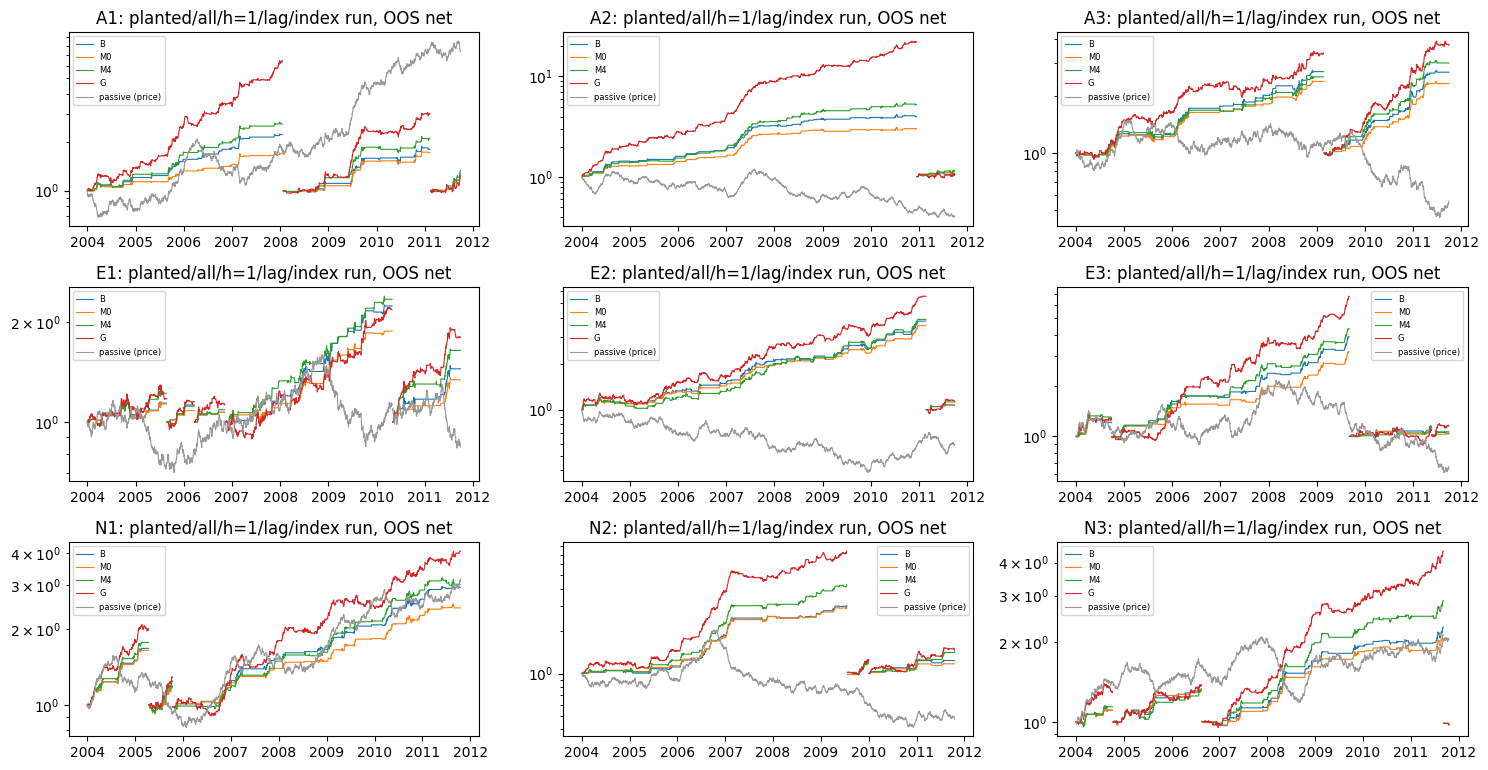

In [22]:
s0 = "planted" if "planted" in results["panels"] else inputs["signal_names"][0]
pool0 = next(iter(results["pools"]))
codes0 = results["pools"][pool0]
h0 = st["horizons"][0]
fig, axes = plt.subplots(-(-len(codes0) // 3), 3, figsize=(15, 2.6 * -(-len(codes0) // 3)), squeeze=False)
for ax, code in zip(axes.flat, codes0):
    for model in ("B", "M0", "M4", "G"):
        d, net = paths[(s0, pool0, h0, "index", model, code)]
        ok = np.isfinite(net)
        seg = np.cumsum(~ok)
        for k in np.unique(seg[ok]):  # contiguous valid segments, each starting from wealth 1
            m_ = ok & (seg == k)
            ax.plot(d[m_], np.cumprod(1 + net[m_]), lw=0.8, color=f"C{['B', 'M0', 'M4', 'G'].index(model)}",
                    label=model if k == np.unique(seg[ok])[0] else None)
    g = results["panels"][s0]
    g = g[(g.code == code) & (g.date >= pd.Timestamp(st["wf_first_test"]))]
    ax.plot(g.date, g.price / g.price.dropna().iloc[0], color="0.6", lw=0.8, label="passive (price)")
    ax.set(title=f"{code}: {s0}/{pool0}/h={h0}/lag/index run, OOS net", yscale="log")
    ax.legend(fontsize=6)
plt.tight_layout()
plt.show()

## Conclusions and real-data handoff

In [23]:
lag_idx = oos[(oos.label == "lag") & (oos.run == "index")]
print("Out-of-sample R² by model (lag labels, index run); controls: zero, mean")
display(lag_idx.pivot_table(index=["signal", "pool", "model"], columns="h", values="R2", sort=False))
print("Median per-index net Sharpe (lag labels, index run) and passive")
display(pnl[pnl.run.isin(["index", "-"])].groupby(["signal", "h", "model"]).sharpe.median().unstack("h"))

Out-of-sample R² by model (lag labels, index run); controls: zero, mean


h                           1         5         20
signal   pool model                               
null_ar1 all  B     -0.0002533 -0.001073 -0.004165
              S     -0.0002392 -0.001235 -0.004964
              s(u)  -0.0003323 -0.001587 -0.006591
              M0    -0.0001486 -0.001001 -0.003278
              M1     -0.000138 -0.001042 -0.004659
              M2    -0.0002926 -0.001144 -0.004215
              M3    -0.0001455 -0.001153 -0.003255
              M4    -0.0003085 -0.001187 -0.005107
              G     -0.0004598 -0.001754 -0.007451
              zero   0.0003206  0.001258  0.001969
              mean           0         0         0
planted  all  B        0.02287   0.05566   0.07598
              S        0.02743   0.07014   0.09621
              s(u)     0.02926   0.09208    0.1391
              M0       0.01765   0.04162   0.05946
              M1       0.02676   0.06598   0.08205
              M2       0.02661   0.06001   0.07422
              M3       0.01977   0.04395   0.06031
              M4       0.02827   0.06742   0.08317
              G        0.03192   0.09481    0.1402
              zero    0.000419  0.001628  0.002265
              mean           0         0         0

Median per-index net Sharpe (lag labels, index run) and passive


h                      1       5       20
signal   model                           
null_ar1 B        -0.3407 -0.3369 -0.2218
         G        -0.6145 -0.7092 -0.5305
         M0       -0.2713 -0.2786 -0.3451
         M1      -0.02263 -0.1034 -0.2666
         M2       -0.2766 -0.2633 -0.3299
         M3       -0.2356 -0.3779  -0.457
         M4       -0.3656   -0.26 -0.3728
         S         -0.385 -0.2876 -0.1549
         passive  -0.0902 -0.0902 -0.0902
         s(u)     -0.2674 -0.4615 -0.3903
planted  B          2.235   2.235   2.262
         G          2.382   2.208   2.245
         M0         2.154   2.141   2.153
         M1         2.343   2.377   2.391
         M2         2.258   2.274   2.296
         M3          2.13   2.133    2.19
         M4         2.372   2.391   2.418
         S          2.558   2.547   2.491
         passive  -0.0902 -0.0902 -0.0902
         s(u)       2.372   2.257   2.257

### Reading of the saved synthetic run (`case="mixture"`, `POOL_MODE="all"`)

These notes describe the saved outputs only; rerun and reread after any change.

* All fourteen exact checks pass: state arithmetic, censoring, causality, pool
  isolation, labels/P&L, drift handling, scaling, spline, bootstrap, reproducibility.
* `planted`: every model beats M0 at every horizon, label, and intercept run, with
  bootstrap intervals below zero. Against binary, only S, M1, M4, and G are below
  zero everywhere. M0 and M3 lose to binary, and `s(u)` and M2 are mixed. `s(u)`
  and G lead at h=20 because a persistent signal's middle region forecasts future
  tail entries.
* `null_ar1`: no signal model beats the training-mean control (R² ≤ 0). Several
  intervals exclude zero on the losing side, which is the estimation cost of
  spline and extra-feature models on a signal with no effect.
* M4 coefficients on raw signals are attenuated relative to the known-state values
  (`E_m` ~0.56 vs 1, `Q` ~0.5 vs 1.5). With known state, recovery is exact (check table).
* Recovery study: binary has the lowest truth error in `flat`, M0 in `graded`. The
  one-session entry gain disappears with lagged labels, while the distributed entry
  keeps part of it after lag. The global regional fit has `L≈0`; regional fits recover
  +0.25 / −0.25 / 0.
* Weight returns: the planted panel trades profitably and the null panel does not.
  This validates the simulation mechanics only.

### Real-data handoff

1. Fill **A** `load_real_data()` and **B** `load_real_signals()` with the tables
   specified there. Keep one return basis per index and leave missing closes as rows.
2. Set `DATA_SOURCE = "real"` and choose `POOL_MODE`.
3. Before the primary run, review and fix every *fixture* setting: `wf_first_test`
   (needs enough history before the first test), `tau_age`/`k_velocity`/`m` against
   the anatomy durations, knots and `lambdas` against the support counts,
   `block_len` against the measured autocorrelation table, and `k_risk`, `w_max`,
   `cost_rate` for the traded instruments.
4. The prefix-invariance check runs on `load_real_signals`. The truth comparison and
   recovery study are skipped automatically, and the exact checks still run on their fixtures.